# Etapa 3: Construção e avaliação dos classificadores

**Disciplina:** Inteligência Artificial — Prof. Cristiane Neri Nobre
**Entrega:** 21/11/2026 | **Valor:** 4,00 pontos
**Equipe:** Grupo 10

**Integrantes:**
- Arthur Soares Rolla
- Carlos Eduardo de Melo Sabino
- Matheus de Almeida Moreira
- Paulo Gabriel de Oliveira Leite
- Samuel Lucas Rodrigues Vieira

Este notebook implementa, compara e audita os três algoritmos de classificação obrigatórios sobre as cinco combinações de pré-processamento e balanceamento definidas a partir da Etapa 2, utilizando exclusivamente `data/treino.csv` e o protocolo comum sem vazamento de dados (`StratifiedGroupKFold`, semente 42).

| Seção | Conteúdo |
|---|---|
| 1 | Protocolo comum, Árvore de Decisão, seleção aninhada de hiperparâmetros e análise de erros |
| 2 | Random Forest, seleção aninhada (com pesos moderados e limiar interno), curva de árvores e comparação com a árvore |
| 3 | Rede Neural MLP, comparação de escalas (`log1p + StandardScaler`), convergência e seleção aninhada |
| 4 | Tabela comparativa estruturada (21 candidatos x 5 dobras) e gráficos comparativos |
| 5 | Critério determinístico de seleção, auditoria metodológica, estabilidade (divisão 137), otimismo e configuração para a Etapa 4 |


## Regras comuns às cinco seções

- Usar exclusivamente os arquivos oficiais em `data/`: este notebook lê somente `treino.csv`; `teste_sem_rotulo.csv` e `modelo_de_submissao.csv` ficam isolados para a Etapa 4.
- O alvo é `class`, com valores `normal` e `anomaly`; não remapear para cinco famílias de ataques.
- Não substituir, reembaralhar ou recriar a separação oficial de treino/teste. Validação interna é permitida **somente dentro do treino**.
- Ajustar imputação, codificação, normalização, balanceamento e limiares apenas no treino de cada dobra.
- `id` identifica o teste e não é atributo preditivo. O teste não tem gabarito disponível à equipe.
- Manter os três sinais operacionais (`score_ids_legado`, `tipo_alerta_soc`, `tempo_resposta_analista_min`) excluídos preventivamente enquanto sua origem e disponibilidade temporal não forem confirmadas com a professora.
- Cada seção entrega código comentado, resultados reais executados do início ao fim e conclusão técnica própria.

## 1. Árvore de Decisão e protocolo comum

**Objetivo:** Definir com a equipe as dobras internas, sementes, métricas e combinações recebidas da etapa 2. Implementar a Árvore de Decisão e avaliá-la nas estratégias escolhidas, sem consultar o teste oficial.

**Entregável:** Resultados por configuração e dobra, parâmetros documentados por validação aninhada e análise dos erros de ambas as classes.


### 1.1 Protocolo comum da etapa 3

O protocolo abaixo vale para os três classificadores (Seções 1, 2 e 3). Ele reproduz exatamente a carga, as transformações e as dobras do notebook 02, para que os resultados das etapas sejam comparáveis.

| Item | Decisão comum | Motivo |
|---|---|---|
| Dados | Somente `data/treino.csv`; o teste oficial não é lido neste notebook | Sem gabarito e sem decisões guiadas pelo teste |
| Preditores | 46 atributos; sinais operacionais (`score_ids_legado`, `tipo_alerta_soc`, `tempo_resposta_analista_min`) excluídos | Risco de vazamento apontado nas etapas 1 e 2; exclusão preventiva mantida |
| Dobras | `StratifiedGroupKFold`, 5 dobras, `shuffle=True`, semente 42, grupo = registro com atributos idênticos | Cópias nunca ficam em lados opostos; mesmas dobras da etapa 2 |
| Sementes | `SEMENTE = 42` em dobras, amostradores e modelos | Reprodutibilidade |
| Ajustes | Imputação, codificação, escala, filtro de conflitos e balanceamento apenas no treino de cada dobra; a validação nunca é filtrada nem balanceada | Sem vazamento e estimativa honesta |
| Métrica principal | F1-macro na validação de cada dobra (média ± desvio entre dobras) | Critério oficial do trabalho |
| Métricas complementares | Precisão, recall e F1 por classe, acurácia, matriz de confusão (TN, FP, FN, TP) e tempos de ajuste/predição | Análise de erros e custo |

As funções `avaliar_modelo`, `montar_pipeline`, os dicionários `CONFIGURACOES` e a lista `INDICES_DOBRAS` ficam disponíveis para todas as seções seguintes.


In [1]:
# Seção 1 - 1.1 Protocolo comum: carga, transformações e dobras (iguais às do notebook 02)
from pathlib import Path
import hashlib
import platform
import time

import numpy as np
import pandas as pd
import sklearn
import imblearn
from IPython.display import display
from imblearn.over_sampling import RandomOverSampler
from imblearn.pipeline import Pipeline as PipelineBalanceado
from imblearn.under_sampling import RandomUnderSampler
from sklearn.base import BaseEstimator, TransformerMixin, clone
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.metrics import accuracy_score, confusion_matrix, precision_recall_fscore_support
from sklearn.model_selection import StratifiedGroupKFold
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.tree import DecisionTreeClassifier

print({"Python": platform.python_version(), "numpy": np.__version__, "pandas": pd.__version__,
       "scikit-learn": sklearn.__version__, "imbalanced-learn": imblearn.__version__})

SEMENTE = 42
N_DOBRAS = 5

project_root = Path.cwd().resolve()
if not (project_root / "data" / "treino.csv").exists():
    project_root = project_root.parent
if not (project_root / "data" / "treino.csv").exists():
    raise FileNotFoundError("Execute na raiz do projeto ou em notebooks/.")
DIR_DADOS = project_root / "data"

COL_ROTULO = "class"
COL_ID = "id"
CLASSES = ["normal", "anomaly"]          # anomaly = classe positiva (1)
COLS_CATEGORICAS = ["protocol_type", "service", "flag"]
SINAIS_OPERACIONAIS = ["score_ids_legado", "tipo_alerta_soc", "tempo_resposta_analista_min"]
COLS_DERIVADAS = ("src_bytes_kb", "dst_bytes_kb", "total_bytes", "same_srv_pct", "protocolo_cod")
# Limites de domínio da documentação do KDD (conhecimento prévio, não aprendidos dos dados).
LIMITES_DOMINIO = {
    **{c: (0, 1) for c in ["serror_rate", "srv_serror_rate", "rerror_rate", "srv_rerror_rate",
                           "same_srv_rate", "diff_srv_rate", "srv_diff_host_rate",
                           "dst_host_same_srv_rate", "dst_host_diff_srv_rate",
                           "dst_host_same_src_port_rate", "dst_host_srv_diff_host_rate",
                           "dst_host_serror_rate", "dst_host_srv_serror_rate",
                           "dst_host_rerror_rate", "dst_host_srv_rerror_rate"]},
    "same_srv_pct": (0, 100),
    "count": (0, 511), "srv_count": (0, 511),
    "dst_host_count": (0, 255), "dst_host_srv_count": (0, 255),
    "duration": (0, np.inf), "src_bytes": (0, np.inf), "dst_bytes": (0, np.inf),
    "total_bytes": (0, np.inf), "src_bytes_kb": (0, np.inf), "dst_bytes_kb": (0, np.inf),
}


def carregar_treino(incluir_operacionais: bool = False):
    """Lê treino.csv sem alterá-lo. Retorna (X, y) com y = 1 para anomaly."""
    df = pd.read_csv(DIR_DADOS / "treino.csv")
    assert set(df[COL_ROTULO]) == set(CLASSES) and df[COL_ROTULO].notna().all()
    assert COL_ID not in df.columns, "id não é atributo preditivo."
    descartar = [COL_ROTULO] + ([] if incluir_operacionais else SINAIS_OPERACIONAIS)
    return df.drop(columns=descartar), (df[COL_ROTULO] == "anomaly").astype(int).rename(COL_ROTULO)


class NormalizarCategorias(BaseEstimator, TransformerMixin):
    """strip + minúsculas nos categóricos ('TCP ' -> 'tcp'). Sem estado; NaN continua NaN."""

    def __init__(self, colunas=tuple(COLS_CATEGORICAS), ativo=True):
        self.colunas = colunas
        self.ativo = ativo

    def fit(self, X, y=None):
        return self

    def transform(self, X):
        X = X.copy()
        for c in self.colunas:
            if c in X:
                serie = X[c].astype(object)
                X[c] = serie.str.strip().str.lower() if self.ativo else serie
        return X


class TratarForaDominio(BaseEstimator, TransformerMixin):
    """'manter' | 'ausente' (vira NaN) | 'recorte' (clip). Limites da documentação."""

    def __init__(self, modo="manter"):
        self.modo = modo

    def fit(self, X, y=None):
        assert self.modo in {"manter", "ausente", "recorte"}
        return self

    def transform(self, X):
        if self.modo == "manter":
            return X
        X = X.copy()
        for c, (lo, hi) in LIMITES_DOMINIO.items():
            if c in X:
                X[c] = (X[c].astype(float).mask((X[c] < lo) | (X[c] > hi)) if self.modo == "ausente"
                        else X[c].clip(lower=lo, upper=hi))
        return X


class RemoverRedundantes(BaseEstimator, TransformerMixin):
    """Remove derivadas determinísticas (lista fixa) e constantes detectadas NO TREINO DA DOBRA."""

    def __init__(self, ativo=True):
        self.ativo = ativo

    def fit(self, X, y=None):
        constantes = [c for c in X.columns if X[c].nunique(dropna=True) <= 1] if self.ativo else []
        self.remover_ = sorted(set(COLS_DERIVADAS).intersection(X.columns) | set(constantes)) if self.ativo else []
        return self

    def transform(self, X):
        return X.drop(columns=self.remover_)


class Log1pNumerico(BaseEstimator, TransformerMixin):
    """Aplica log1p com sinal preservado (igual a log1p para valores >= 0, seguro contra negativos em P0)."""

    def fit(self, X, y=None):
        return self

    def transform(self, X):
        arr = np.asarray(X, dtype=float)
        return np.sign(arr) * np.log1p(np.abs(arr))

    def get_feature_names_out(self, input_features=None):
        return np.asarray(input_features, dtype=object) if input_features is not None else None


def _eh_categorica(X):
    return [c for c in X.columns if not pd.api.types.is_numeric_dtype(X[c])]


def _eh_numerica(X):
    return [c for c in X.columns if pd.api.types.is_numeric_dtype(X[c])]


def montar_preprocessamento(normalizar_categorias=True, fora_dominio="manter", remover_redundantes=False,
                            imputacao_num="mediana", imputacao_cat="constante",
                            codificacao="onehot", escala=None):
    """Pré-processamento das partes 1 e 3 do notebook 02, com codificação e escala selecionáveis.

    codificacao: 'onehot' | 'onehot_raras' (categorias com < 100 registros no treino da dobra agrupadas)
    escala:      None | 'standard' | 'log1p_standard'
    """
    imp_num = SimpleImputer(strategy="median", add_indicator=(imputacao_num == "mediana+indicador"))
    if escala == "standard":
        etapas_num = [("imp", imp_num), ("escala", StandardScaler())]
    elif escala == "log1p_standard":
        etapas_num = [("imp", imp_num), ("log1p", Log1pNumerico()), ("escala", StandardScaler())]
    elif escala is None:
        etapas_num = [("imp", imp_num), ("escala", "passthrough")]
    else:
        raise ValueError(f"Escala desconhecida: {escala}")
    numerico = Pipeline(etapas_num)
    imp_cat = (SimpleImputer(strategy="constant", fill_value="__ausente__") if imputacao_cat == "constante"
               else SimpleImputer(strategy="most_frequent"))
    ohe = (OneHotEncoder(handle_unknown="infrequent_if_exist", min_frequency=100, sparse_output=False)
           if codificacao == "onehot_raras" else OneHotEncoder(handle_unknown="ignore", sparse_output=False))
    colunas = ColumnTransformer([
        ("num", numerico, _eh_numerica),
        ("cat", Pipeline([("imp", imp_cat), ("ohe", ohe)]), _eh_categorica),
    ], verbose_feature_names_out=False)
    return Pipeline([
        ("categorias", NormalizarCategorias(ativo=normalizar_categorias)),
        ("dominio", TratarForaDominio(modo=fora_dominio)),
        ("redundantes", RemoverRedundantes(ativo=remover_redundantes)),
        ("imputacao_codificacao", colunas),
    ])


def chave_registro(X):
    """Identificador de registros com atributos idênticos (categorias normalizadas, NaN como valor)."""
    Xn = NormalizarCategorias().transform(X)
    return pd.Series(pd.factorize(pd.util.hash_pandas_object(Xn, index=False))[0], index=X.index)


def filtrar_linhas_treino(X, y, estrategia="todas"):
    """'todas' | 'sem_conflitos': remove, só do treino da dobra, grupos idênticos com classes divergentes."""
    if estrategia == "todas":
        return X, y
    if estrategia != "sem_conflitos":
        raise ValueError(estrategia)
    chave = chave_registro(X)
    manter = ~chave.map(y.groupby(chave).nunique()).gt(1)
    return X[manter], y[manter]


X_treino, y_treino = carregar_treino()
grupos_treino = chave_registro(X_treino)
DOBRAS = StratifiedGroupKFold(n_splits=N_DOBRAS, shuffle=True, random_state=SEMENTE)
INDICES_DOBRAS = list(DOBRAS.split(X_treino, y_treino, grupos_treino))

# Auditoria das dobras: partição completa, grupos disjuntos e proporção de anomalias estável.
dobra_de_cada_linha = np.empty(len(X_treino), dtype=int)
auditoria_dobras = []
for i, (itr, iva) in enumerate(INDICES_DOBRAS, start=1):
    assert set(grupos_treino.iloc[itr]).isdisjoint(grupos_treino.iloc[iva])
    dobra_de_cada_linha[iva] = i
    auditoria_dobras.append({"dobra": i, "n_treino": len(itr), "n_validacao": len(iva),
                             "anomalias_validacao": int(y_treino.iloc[iva].sum()),
                             "pct_anomaly_validacao": 100 * y_treino.iloc[iva].mean()})
assert sorted(np.concatenate([iva for _, iva in INDICES_DOBRAS])) == list(range(len(X_treino)))
# Impressão digital das dobras: garante que todas as seções (e a etapa 4) usam a mesma divisão.
ASSINATURA_DOBRAS = hashlib.sha256(dobra_de_cada_linha.tobytes()).hexdigest()[:16]

print(f"Treino: {X_treino.shape[0]:,} linhas x {X_treino.shape[1]} atributos; "
      f"{grupos_treino.nunique():,} registros distintos (grupos)")
print("Assinatura das dobras:", ASSINATURA_DOBRAS)
display(pd.DataFrame(auditoria_dobras).round(3))


{'Python': '3.13.14', 'numpy': '2.5.2', 'pandas': '3.0.5', 'scikit-learn': '1.9.0', 'imbalanced-learn': '0.14.2'}


Treino: 69,833 linhas x 46 atributos; 56,766 registros distintos (grupos)
Assinatura das dobras: 8a814c72d149c698


,dobra,n_treino,n_validacao,anomalias_validacao,pct_anomaly_validacao
0,1,55866,13967,816,5.842
1,2,55865,13968,816,5.842
2,3,55867,13966,816,5.843
3,4,55867,13966,816,5.843
4,5,55867,13966,815,5.836


### 1.2 Combinações recebidas da etapa 2 e avaliador comum

As combinações abaixo foram definidas a partir das conclusões do notebook 02. Cada uma altera **um fator** em relação à anterior, para que a diferença de desempenho possa ser atribuída a ele.

| Código | Pré-processamento | Balanceamento | Origem na etapa 2 |
|---|---|---|---|
| P0 | Referência R0: categorias brutas, fora do domínio mantido, todas as colunas e linhas, One-Hot | nenhum | Parte 1 (referência) |
| P1 | `CONFIG_M1`: categorias normalizadas, fora do domínio (`ausente`), sem derivadas/constantes, mediana + `__ausente__`, treino sem conflitos | nenhum | Parte 1 (limpeza proposta) |
| P2 | P1 + One-Hot com categorias raras (`< 100` no treino da dobra) agrupadas | nenhum | Parte 3 (redução de cardinalidade) |
| P3 | P2 | `RandomOverSampler` 1:1 | Parte 2 (superamostragem) |
| P4 | P2 | `RandomUnderSampler` 1:1 | Parte 2 (subamostragem) |

Notas de transição entre as etapas 2 e 3:
- **SMOTENC + Tomek** não foi incluído nesta grade comum porque na etapa 2 não superou a ausência de balanceamento e custou de 20 a 30 vezes mais por dobra.
- **Redução de dimensionalidade (PCA)** foi avaliada nas partes 4 e 5 do notebook 02 (com 25 e 50 componentes) e descartada por degradar o F1-macro em todas as dobras dos modelos testados.
- **Pesos moderados de classe** (recomendados na parte 5 da etapa 2 por dependerem de cada classificador) são avaliados diretamente na validação aninhada de hiperparâmetros da Árvore (seção 1.4) e da Random Forest (seção 2.3).


In [2]:
# Seção 1 - 1.2 Combinações da etapa 2 e avaliador comum (reutilizado nas seções 2 e 3)
CONFIG_R0 = dict(normalizar_categorias=False, fora_dominio="manter", remover_redundantes=False,
                 imputacao_num="mediana", imputacao_cat="constante", codificacao="onehot",
                 linhas_treino="todas", balanceamento=None)
CONFIG_M1 = dict(normalizar_categorias=True, fora_dominio="ausente", remover_redundantes=True,
                 imputacao_num="mediana", imputacao_cat="constante", codificacao="onehot",
                 linhas_treino="sem_conflitos", balanceamento=None)
CONFIGURACOES = {
    "P0 referência R0": CONFIG_R0,
    "P1 tratamento M1": CONFIG_M1,
    "P2 P1 + raras agrupadas": {**CONFIG_M1, "codificacao": "onehot_raras"},
    "P3 P2 + ROS": {**CONFIG_M1, "codificacao": "onehot_raras", "balanceamento": "ROS"},
    "P4 P2 + RUS": {**CONFIG_M1, "codificacao": "onehot_raras", "balanceamento": "RUS"},
}
CONFIG_PRINCIPAL = "P2 P1 + raras agrupadas"
LIMIARES_BUSCA = np.round(np.linspace(0.20, 0.70, 51), 2)


def montar_pipeline(config, modelo, escala=None):
    """Pré-processamento + balanceamento opcional (só no fit) + modelo. Tudo é ajustado no treino da dobra."""
    prep_params = {k: v for k, v in config.items() if k not in ("linhas_treino", "balanceamento")}
    amostradores = {
        None: "passthrough",
        "ROS": RandomOverSampler(sampling_strategy=1.0, random_state=SEMENTE),
        "RUS": RandomUnderSampler(sampling_strategy=1.0, replacement=False, random_state=SEMENTE),
    }
    # imblearn não aceita Pipeline aninhado como etapa intermediária: as etapas do pré-processamento
    # entram "achatadas" (categorias, dominio, redundantes, imputacao_codificacao).
    prep = montar_preprocessamento(**prep_params, escala=escala)
    return PipelineBalanceado(prep.steps + [
        ("balanceamento", amostradores[config["balanceamento"]]),
        ("modelo", clone(modelo)),
    ])


def metricas_classificacao(y_true, y_pred):
    """F1-macro (principal), métricas por classe, acurácia e matriz de confusão (anomaly = positivo)."""
    p, r, f, s = precision_recall_fscore_support(y_true, y_pred, labels=[0, 1], zero_division=0)
    tn, fp, fn, tp = confusion_matrix(y_true, y_pred, labels=[0, 1]).ravel()
    m = {"f1_macro": float(f.mean()), "acuracia": accuracy_score(y_true, y_pred),
         "TN": int(tn), "FP": int(fp), "FN": int(fn), "TP": int(tp)}
    for j, classe in enumerate(CLASSES):
        m.update({f"precisao_{classe}": p[j], f"recall_{classe}": r[j], f"f1_{classe}": f[j]})
    return m


def ajustar_limiar_f1_macro(y_true, prob_pos, limiares=LIMIARES_BUSCA):
    """Escolhe o limiar de maior F1-macro; em empate exato, prefere o mais próximo de 0,5 e depois o menor."""
    y_arr = np.asarray(y_true)
    p_arr = np.asarray(prob_pos)
    melhor_limiar, melhor_f1 = 0.5, -1.0
    for t in limiares:
        f1 = metricas_classificacao(y_arr, (p_arr >= t).astype(int))["f1_macro"]
        if f1 > melhor_f1 + 1e-12 or (
            abs(f1 - melhor_f1) <= 1e-12
            and (abs(float(t) - 0.5), float(t)) < (abs(melhor_limiar - 0.5), melhor_limiar)
        ):
            melhor_limiar, melhor_f1 = float(t), float(f1)
    return melhor_limiar, melhor_f1


def avaliar_modelo(modelo, nome_modelo, configuracoes=None, dobras=None, escala=None, guardar=False):
    """Protocolo comum: para cada combinação e dobra, ajusta no treino (filtrado) e mede na validação intacta.

    Retorna (por_dobra, oof): métricas por combinação x dobra e, se guardar=True, as predições fora da
    dobra e os pipelines ajustados por combinação (para análise de erros e importâncias).
    """
    configuracoes = CONFIGURACOES if configuracoes is None else configuracoes
    dobras = INDICES_DOBRAS if dobras is None else dobras
    linhas, oof = [], {}
    for nome_cfg, cfg in configuracoes.items():
        pred_oof = np.full(len(X_treino), -1)
        pipes = []
        for dobra, (itr, iva) in enumerate(dobras, start=1):
            X_tr, y_tr = filtrar_linhas_treino(X_treino.iloc[itr], y_treino.iloc[itr], cfg["linhas_treino"])
            X_va, y_va = X_treino.iloc[iva], y_treino.iloc[iva]
            pipe = montar_pipeline(cfg, modelo, escala)
            t0 = time.perf_counter()
            pipe.fit(X_tr, y_tr)
            t1 = time.perf_counter()
            pred = pipe.predict(X_va)
            t2 = time.perf_counter()
            pred_oof[iva] = pred
            linhas.append({"modelo": nome_modelo, "configuracao": nome_cfg, "dobra": dobra,
                           **metricas_classificacao(y_va, pred),
                           "n_treino_ajuste": len(X_tr), "segundos_ajuste": t1 - t0, "segundos_predicao": t2 - t1})
            if guardar:
                pipes.append(pipe)
        assert (pred_oof[np.concatenate([iva for _, iva in dobras])] >= 0).all()
        oof[nome_cfg] = {"pred": pred_oof, "pipes": pipes}
    return pd.DataFrame(linhas), oof


def resumir(por_dobra):
    """Média ± desvio entre dobras, por modelo e combinação (formato comum para a Seção 4)."""
    metr = ["f1_macro", "precisao_normal", "recall_normal", "f1_normal",
            "precisao_anomaly", "recall_anomaly", "f1_anomaly", "acuracia"]
    agg = {"f1_macro_media": ("f1_macro", "mean"), "f1_macro_dp": ("f1_macro", "std"),
           **{m: (m, "mean") for m in metr[1:]},
           "FP": ("FP", "sum"), "FN": ("FN", "sum"),
           "seg_ajuste": ("segundos_ajuste", "mean"), "seg_predicao": ("segundos_predicao", "mean")}
    return por_dobra.groupby(["modelo", "configuracao"], sort=False).agg(**agg).reset_index()


print("Combinações:", list(CONFIGURACOES))


Combinações: ['P0 referência R0', 'P1 tratamento M1', 'P2 P1 + raras agrupadas', 'P3 P2 + ROS', 'P4 P2 + RUS']


### 1.3 Árvore de Decisão nas combinações da etapa 2

Primeiro, a árvore usa os parâmetros padrão do scikit-learn (gini sem limite de profundidade, min_samples_leaf=1 e random_state=42), mesmo modelo de referência da etapa 2, então a variação entre combinações vem do pré-processamento e do balanceamento, e não de ajuste do modelo. 

A escolha de hiperparâmetros é tratada separadamente na seção 1.4.

In [3]:
# Seção 1 - 1.3 Árvore de Decisão (parâmetros padrão) em todas as combinações, mesmas dobras
ARVORE_PADRAO = DecisionTreeClassifier(random_state=SEMENTE)

por_dobra_arvore, oof_arvore = avaliar_modelo(ARVORE_PADRAO, "Árvore (padrão)", guardar=True)
ref_p0 = por_dobra_arvore[por_dobra_arvore.configuracao == "P0 referência R0"].set_index("dobra")["f1_macro"]
por_dobra_arvore["delta_vs_P0"] = por_dobra_arvore.f1_macro - por_dobra_arvore.dobra.map(ref_p0)

tabela_arvore = resumir(por_dobra_arvore)
tabela_arvore["dobras_melhores_que_P0"] = (por_dobra_arvore.groupby("configuracao", sort=False)
                                          .delta_vs_P0.apply(lambda d: int((d > 0).sum())).values)
with pd.option_context("display.float_format", "{:.4f}".format, "display.max_columns", None, "display.width", 250):
    display(tabela_arvore)
    print("F1-macro por dobra:")
    display(por_dobra_arvore.pivot(index="configuracao", columns="dobra", values="f1_macro").reindex(CONFIGURACOES))
    print("Matriz de confusão por dobra (combinação principal):")
    display(por_dobra_arvore.loc[por_dobra_arvore.configuracao == CONFIG_PRINCIPAL,
                                 ["dobra", "TN", "FP", "FN", "TP", "n_treino_ajuste",
                                  "segundos_ajuste", "segundos_predicao"]].set_index("dobra"))

# Profundidade e número de folhas das árvores ajustadas (combinação principal).
estrutura = pd.DataFrame([{"dobra": i, "profundidade": p.named_steps["modelo"].get_depth(),
                           "folhas": p.named_steps["modelo"].get_n_leaves()}
                          for i, p in enumerate(oof_arvore[CONFIG_PRINCIPAL]["pipes"], start=1)])
display(estrutura.set_index("dobra").T)


,modelo,configuracao,f1_macro_media,f1_macro_dp,precisao_normal,recall_normal,f1_normal,precisao_anomaly,recall_anomaly,f1_anomaly,acuracia,FP,FN,seg_ajuste,seg_predicao,dobras_melhores_que_P0
0,Árvore (padrão),P0 referência R0,0.8050,0.0056,0.9726,0.9876,0.9800,0.7341,0.5519,0.6299,0.9621,816,1828,1.0926,0.0114,0
1,Árvore (padrão),P1 tratamento M1,0.8706,0.0044,0.9859,0.9832,0.9846,0.7407,0.7735,0.7566,0.9709,1105,924,0.5970,0.0172,5
2,Árvore (padrão),P2 P1 + raras agrupadas,0.8730,0.0038,0.9863,0.9833,0.9848,0.7434,0.7801,0.7612,0.9714,1099,897,0.4115,0.0160,5
3,Árvore (padrão),P3 P2 + ROS,0.8630,0.0045,0.9844,0.9833,0.9839,0.7356,0.7490,0.7422,0.9696,1098,1024,0.3999,0.0160,5
4,Árvore (padrão),P4 P2 + RUS,0.7973,0.0092,0.9880,0.9510,0.9691,0.5081,0.8142,0.6255,0.9430,3223,758,0.1408,0.0157,1


F1-macro por dobra:


dobra,1,2,3,4,5
configuracao,,,,,
P0 referência R0,0.7987,0.8108,0.8109,0.8012,0.8033
P1 tratamento M1,0.8685,0.8703,0.8779,0.8664,0.8699
P2 P1 + raras agrupadas,0.8715,0.8746,0.8788,0.8692,0.8709
P3 P2 + ROS,0.8563,0.8683,0.8650,0.8640,0.8615
P4 P2 + RUS,0.8105,0.8004,0.7858,0.7922,0.7977


Matriz de confusão por dobra (combinação principal):


,TN,FP,FN,TP,n_treino_ajuste,segundos_ajuste,segundos_predicao
dobra,,,,,,,
1,12921,230,177,639,52884,0.4267,0.0160
2,12927,225,172,644,52879,0.3846,0.0159
3,12937,213,169,647,52864,0.4228,0.0166
4,12946,204,199,617,52891,0.3880,0.0154
5,12924,227,180,635,52894,0.4355,0.0160


dobra,1,2,3,4,5
profundidade,26,24,26,24,27
folhas,204,214,223,210,229


### 1.4 Hiperparâmetros por validação aninhada

Para evitar que a árvore fique muito complexa e para avaliar também o peso moderado sugerido na etapa 2 (`class_weight={0: 1.0, 1: 2.0}`), testamos 27 combinações de parâmetros por validação aninhada. Usamos 3 divisões internas por grupos para selecionar a melhor configuração pelo F1-macro; em seguida, a árvore escolhida é reajustada no treino externo e avaliada na dobra externa.

Todo o pré-processamento e a filtragem de conflitos são refeitos em cada divisão interna e externa sobre a combinação principal P2.


In [4]:
# Seção 1 - 1.4 Seleção aninhada de hiperparâmetros da árvore (combinação principal P2)
from itertools import product

GRADE_ARVORE = [dict(max_depth=d, min_samples_leaf=f, class_weight=w)
                for d, f, w in product([None, 20, 10], [1, 5, 20], [None, {0: 1.0, 1: 2.0}, "balanced"])]
cfg_p2 = CONFIGURACOES[CONFIG_PRINCIPAL]
DOBRAS_INTERNAS = StratifiedGroupKFold(n_splits=3, shuffle=True, random_state=SEMENTE)


def rotulo(v):
    """Converte valores da grade (None, dict, tuple, número) em rótulos hashable para tabelas."""
    if v is None or (isinstance(v, float) and np.isnan(v)):
        return "None"
    if isinstance(v, dict):
        return f"peso_{v[1]:g}"
    if isinstance(v, tuple):
        return str(v)
    return str(v).removesuffix(".0")


def f1_macro_grade(X_tr, y_tr, X_va, y_va):
    """Ajusta o pré-processamento uma vez e avalia todas as árvores da grade nessa divisão."""
    X_tr, y_tr = filtrar_linhas_treino(X_tr, y_tr, cfg_p2["linhas_treino"])
    prep_params = {k: v for k, v in cfg_p2.items() if k not in ("linhas_treino", "balanceamento")}
    prep = montar_preprocessamento(**prep_params).fit(X_tr, y_tr)
    Z_tr, Z_va = prep.transform(X_tr), prep.transform(X_va)
    return [metricas_classificacao(y_va, DecisionTreeClassifier(random_state=SEMENTE, **p)
                                   .fit(Z_tr, y_tr).predict(Z_va))["f1_macro"] for p in GRADE_ARVORE]


inicio = time.perf_counter()
registros_internos, por_dobra_aninhada = [], []
for dobra, (itr, iva) in enumerate(INDICES_DOBRAS, start=1):
    X_ext, y_ext, g_ext = X_treino.iloc[itr], y_treino.iloc[itr], grupos_treino.iloc[itr]
    notas = np.array([f1_macro_grade(X_ext.iloc[a], y_ext.iloc[a], X_ext.iloc[b], y_ext.iloc[b])
                      for a, b in DOBRAS_INTERNAS.split(X_ext, y_ext, g_ext)])
    media_interna = notas.mean(axis=0)
    for p, m in zip(GRADE_ARVORE, media_interna):
        registros_internos.append({"dobra": dobra, **p, "f1_macro_interno": m})
    melhor = GRADE_ARVORE[int(np.argmax(media_interna))]       # empate: a 1ª da grade (mais simples na ordem)
    arvore = DecisionTreeClassifier(random_state=SEMENTE, **melhor)
    res, _ = avaliar_modelo(arvore, "Árvore (aninhada)", {CONFIG_PRINCIPAL: cfg_p2}, dobras=[(itr, iva)])
    res["dobra"] = dobra
    por_dobra_aninhada.append(res.assign(**{f"param_{k}": rotulo(v) for k, v in melhor.items()},
                                         f1_macro_interno=media_interna.max()))
por_dobra_aninhada = pd.concat(por_dobra_aninhada, ignore_index=True)
grade_interna = pd.DataFrame(registros_internos)
print(f"Seleção aninhada concluída em {time.perf_counter() - inicio:.0f} s.")

with pd.option_context("display.float_format", "{:.4f}".format, "display.width", 250):
    print("Parâmetros escolhidos em cada dobra externa (escolha feita só com o treino externo):")
    display(por_dobra_aninhada[["dobra", "param_max_depth", "param_min_samples_leaf", "param_class_weight",
                                "f1_macro_interno", "f1_macro", "f1_normal", "f1_anomaly", "FP", "FN"]])
    padrao_p2 = por_dobra_arvore[por_dobra_arvore.configuracao == CONFIG_PRINCIPAL].set_index("dobra").f1_macro
    print(f"F1-macro externo - árvore aninhada: {por_dobra_aninhada.f1_macro.mean():.4f} ± "
          f"{por_dobra_aninhada.f1_macro.std():.4f}; árvore padrão: {padrao_p2.mean():.4f} ± {padrao_p2.std():.4f}; "
          f"aninhada melhor em {(por_dobra_aninhada.set_index('dobra').f1_macro > padrao_p2).sum()}/{N_DOBRAS} dobras")
    print("F1-macro interno médio de cada ponto da grade (média das 5 dobras externas):")
    display(grade_interna.assign(max_depth=grade_interna.max_depth.map(rotulo),
                                 class_weight=grade_interna.class_weight.map(rotulo))
            .pivot_table(index=["class_weight", "max_depth"], columns="min_samples_leaf",
                         values="f1_macro_interno", aggfunc="mean"))


Seleção aninhada concluída em 65 s.
Parâmetros escolhidos em cada dobra externa (escolha feita só com o treino externo):


,dobra,param_max_depth,param_min_samples_leaf,param_class_weight,f1_macro_interno,f1_macro,f1_normal,f1_anomaly,FP,FN
0,1,None,1,None,0.8701,0.8715,0.9845,0.7585,230,177
1,2,20,1,None,0.8672,0.8742,0.9849,0.7635,222,175
2,3,None,1,None,0.8689,0.8788,0.9855,0.7721,213,169
3,4,None,1,peso_2,0.8687,0.8673,0.9844,0.7502,207,202
4,5,None,1,None,0.8679,0.8709,0.9845,0.7573,227,180


F1-macro externo - árvore aninhada: 0.8725 ± 0.0043; árvore padrão: 0.8730 ± 0.0038; aninhada melhor em 0/5 dobras
F1-macro interno médio de cada ponto da grade (média das 5 dobras externas):


min_samples_leaf           1      5      20
class_weight max_depth                     
None         10        0.8590 0.8563 0.8465
             20        0.8683 0.8648 0.8484
             None      0.8680 0.8648 0.8482
balanced     10        0.8459 0.8409 0.8118
             20        0.8599 0.8517 0.8128
             None      0.8601 0.8515 0.8128
peso_2       10        0.8602 0.8591 0.8523
             20        0.8675 0.8650 0.8532
             None      0.8675 0.8647 0.8532

### 1.5 Análise dos erros das duas classes

Analisamos as previsões da árvore padrão na combinação P2, garantindo que cada registro fosse avaliado por um modelo que não o utilizou no treinamento. Essa análise serve apenas para identificar os erros, sem alterar o modelo.

Também separamos os erros relacionados aos grupos conflitantes, que possuem atributos iguais, mas classes diferentes. Como esses registros recebem a mesma previsão, pelo menos um erro por grupo é inevitável.

In [5]:
# Seção 1 - 1.5 Análise de erros (predições fora da dobra, árvore padrão, combinação P2)
pred_p2 = pd.Series(oof_arvore[CONFIG_PRINCIPAL]["pred"], index=X_treino.index)
perfil = y_treino.groupby(grupos_treino).agg(["size", "nunique"])
em_conflito = grupos_treino.map(perfil["nunique"]).gt(1)          # diagnóstico, não usado para decidir nada

tipo = np.select([(y_treino == 1) & (pred_p2 == 1), (y_treino == 0) & (pred_p2 == 0),
                  (y_treino == 0) & (pred_p2 == 1)], ["TP", "TN", "FP"], default="FN")
analise = pd.DataFrame({"tipo": tipo, "em_conflito": em_conflito,
                        "dobra": dobra_de_cada_linha}, index=X_treino.index)

print("Matriz de confusão agregada (linhas = real, colunas = previsto):")
display(pd.crosstab(y_treino.map(dict(enumerate(CLASSES))).rename("real"),
                    pred_p2.map(dict(enumerate(CLASSES))).rename("previsto")).loc[CLASSES, CLASSES])
print("Erros dentro e fora de grupos conflitantes:")
display(pd.crosstab(analise.tipo, analise.em_conflito.map({True: "em conflito", False: "sem conflito"}),
                    margins=True, margins_name="total"))

# F1-macro só nas linhas sem conflito: mostra quanto do erro vem do ruído de rótulo irredutível.
sem = ~em_conflito
f1_sem_conflito = metricas_classificacao(y_treino[sem], pred_p2[sem])
f1_total = metricas_classificacao(y_treino, pred_p2)
print(f"F1-macro fora da dobra: todas as linhas {f1_total['f1_macro']:.4f} | "
      f"somente linhas sem conflito {f1_sem_conflito['f1_macro']:.4f} "
      f"(F1 anomaly {f1_total['f1_anomaly']:.4f} -> {f1_sem_conflito['f1_anomaly']:.4f})")

# Onde ficam os erros fora dos conflitos: por protocolo, flag e serviço (categorias normalizadas).
Xn = NormalizarCategorias().transform(X_treino)
erros_sem_conflito = analise[sem]
for col in ["protocol_type", "flag", "service"]:
    tab = pd.crosstab(Xn.loc[sem, col].fillna("__ausente__"), erros_sem_conflito.tipo)
    tab = tab.reindex(columns=["TN", "FP", "FN", "TP"], fill_value=0)
    tab["anomalias"] = tab.FN + tab.TP
    tab["recall_anomaly"] = tab.TP / tab.anomalias.replace(0, np.nan)
    tab["taxa_FP_normal"] = tab.FP / (tab.TN + tab.FP).replace(0, np.nan)
    print(f"Erros sem conflito por {col} (10 categorias com mais erros):")
    with pd.option_context("display.float_format", "{:.3f}".format):
        display(tab.assign(erros=tab.FP + tab.FN).sort_values("erros", ascending=False).head(10))

# Importância média (redução de impureza) dos atributos nas 5 árvores da combinação P2.
importancias = pd.concat([
    pd.Series(p.named_steps["modelo"].feature_importances_,
              index=p.named_steps["imputacao_codificacao"].get_feature_names_out())
    for p in oof_arvore[CONFIG_PRINCIPAL]["pipes"]], axis=1).fillna(0)
importancia_arvore = pd.DataFrame({"media": importancias.mean(axis=1), "dp": importancias.std(axis=1)})
print("15 atributos mais importantes (média ± dp entre dobras):")
display(importancia_arvore.sort_values("media", ascending=False).head(15).round(4))


Matriz de confusão agregada (linhas = real, colunas = previsto):


previsto,normal,anomaly
real,,
normal,64655,1099
anomaly,897,3182


Erros dentro e fora de grupos conflitantes:


em_conflito,em conflito,sem conflito,total
tipo,,,
FN,763,134,897
FP,954,145,1099
TN,880,63775,64655
TP,1133,2049,3182
total,3730,66103,69833


F1-macro fora da dobra: todas as linhas 0.8730 | somente linhas sem conflito 0.9670 (F1 anomaly 0.7612 -> 0.9363)
Erros sem conflito por protocol_type (10 categorias com mais erros):


tipo,TN,FP,FN,TP,anomalias,recall_anomaly,taxa_FP_normal,erros
protocol_type,,,,,,,,
tcp,50951,84,79,1776,1855,0.957,0.002,163
udp,11716,38,42,43,85,0.506,0.003,80
icmp,1108,23,13,230,243,0.947,0.020,36


... (2 outputs left out)

Erros sem conflito por service (10 categorias com mais erros):


tipo,TN,FP,FN,TP,anomalias,recall_anomaly,taxa_FP_normal,erros
service,,,,,,,,
private,1357,36,39,699,738,0.947,0.026,75
__ausente__,4010,15,17,132,149,0.886,0.004,32
http,35037,23,8,122,130,0.938,0.001,31
ftp_data,4054,13,12,45,57,0.789,0.003,25
ecr_i,156,12,10,73,83,0.880,0.071,22
telnet,717,8,11,76,87,0.874,0.011,19
other,1987,7,10,64,74,0.865,0.004,17
smtp,5919,5,8,6,14,0.429,0.001,13
eco_i,347,7,1,118,119,0.992,0.020,8


15 atributos mais importantes (média ± dp entre dobras):


,media,dp
dst_host_srv_serror_rate,0.4697,0.0106
same_srv_rate,0.0960,0.0058
srv_count,0.0657,0.0036
flag_sf,0.0603,0.0056
dst_bytes,0.0342,0.0072
src_bytes,0.0277,0.0048
dst_host_rerror_rate,0.0217,0.0062
protocol_type_icmp,0.0187,0.0011
protocol_type_tcp,0.0184,0.0160
count,0.0183,0.0063


In [6]:
# Seção 1 - 1.6 Itens compartilhados com as Seções 2 e 3 (mesmo protocolo, sem consultar o teste)
compartilhado = {
    "INDICES_DOBRAS": f"{len(INDICES_DOBRAS)} dobras, assinatura {ASSINATURA_DOBRAS}",
    "CONFIGURACOES": ", ".join(CONFIGURACOES),
    "CONFIG_PRINCIPAL": CONFIG_PRINCIPAL,
    "avaliar_modelo(modelo, nome, configuracoes, dobras, escala)": "retorna métricas por dobra + predições fora da dobra",
    "resumir(por_dobra)": "tabela média ± dp no formato comum",
    "por_dobra_arvore / tabela_arvore": f"{len(por_dobra_arvore)} linhas / {len(tabela_arvore)} linhas",
    "por_dobra_aninhada": "árvore com hiperparâmetros escolhidos por validação aninhada",
}
display(pd.Series(compartilhado, name="disponível").to_frame())


,disponível
INDICES_DOBRAS,"5 dobras, assinatura 8a814c72d149c698"
CONFIGURACOES,"P0 referência R0, P1 tratamento M1, P2 P1 + ra..."
CONFIG_PRINCIPAL,P2 P1 + raras agrupadas
"avaliar_modelo(modelo, nome, configuracoes, dobras, escala)",retorna métricas por dobra + predições fora da...
resumir(por_dobra),tabela média ± dp no formato comum
por_dobra_arvore / tabela_arvore,25 linhas / 5 linhas
por_dobra_aninhada,árvore com hiperparâmetros escolhidos por vali...


### Resultados e justificativa — Seção 1 (Árvore de Decisão)

**Protocolo comum (1.1–1.2).** As dobras são exatamente as mesmas da etapa 2: `StratifiedGroupKFold` com 5 dobras, semente 42 e grupos formados por registros idênticos (56.766 grupos em 69.833 linhas). Cada dobra de validação tem 5,84% de `anomaly` e nenhum grupo dividido entre treino e validação. A assinatura `8a814c72d149c698` confirma que todas as seções (e a etapa 4) usam exatamente a mesma divisão. Os resultados reproduzem a etapa 2 (`P0 = 0,8050`, `P1 = 0,8706`, `P2 = 0,8730`).

**Árvore padrão nas combinações (1.3).** F1-macro médio ± desvio em 5 dobras:

| Combinação | F1-macro | F1 normal | F1 anomaly | Precisão / recall anomaly | FP / FN (soma) | Dobras > P0 |
|---|---:|---:|---:|---:|---:|---:|
| P0 referência R0 | 0,8050 ± 0,0056 | 0,9800 | 0,6299 | 0,734 / 0,552 | 816 / 1.828 | - |
| P1 tratamento M1 | 0,8706 ± 0,0044 | 0,9846 | 0,7566 | 0,741 / 0,774 | 1.105 / 924 | 5/5 |
| **P2 P1 + raras agrupadas** | **0,8730 ± 0,0038** | 0,9848 | 0,7612 | 0,743 / 0,780 | 1.099 / 897 | 5/5 |
| P3 P2 + ROS | 0,8630 ± 0,0045 | 0,9839 | 0,7422 | 0,736 / 0,749 | 1.098 / 1.024 | 5/5 |
| P4 P2 + RUS | 0,7973 ± 0,0092 | 0,9691 | 0,6255 | 0,508 / 0,814 | 3.223 / 758 | 1/5 |

O maior ganho vem da etapa 2 (P0 → P1): a remoção de conflitos no treino eleva o recall de `anomaly` de 0,552 para 0,774. O agrupamento de categorias raras acrescenta um ganho pequeno (+0,0024), mas presente nas 5 dobras, reduzindo a dimensão de 117 para ~66 colunas. Para a árvore única, nenhum balanceamento por reamostragem ajudou: o ROS duplica anomalias sem trazer informação nova e perde recall e F1, enquanto o RUS descarta ~97% dos normais, elevando o recall para 0,814 ao custo de derrubar a precisão para 0,508 e triplicar os falsos positivos. **P2 sem balanceamento é a combinação mais forte para a Árvore de Decisão.**

**Hiperparâmetros (1.4).** A árvore sem limite chega a profundidade 24–27 e 204–229 folhas. Na seleção aninhada com grade de 27 pontos (incluindo o peso moderado `{0: 1.0, 1: 2.0}`), a busca interna escolheu `max_depth=None, min_samples_leaf=1, class_weight=None` em 3 dobras, `max_depth=20, min_samples_leaf=1, class_weight=None` na dobra 2 e `max_depth=None, min_samples_leaf=1, class_weight=peso_2` na dobra 4. O F1-macro externo foi `0,8725 ± 0,0043`, ligeiramente abaixo da árvore padrão (`0,8730 ± 0,0038`, 0/5 dobras melhores). Podar (`min_samples_leaf=20` → ~0,848; `max_depth=10` → ~0,859) ou usar `class_weight="balanced"` (~0,813–0,860) piorou o desempenho interno de forma consistente. **Parâmetros documentados:** `DecisionTreeClassifier(criterion="gini", max_depth=None, min_samples_leaf=1, class_weight=None, random_state=42)`.

**Análise de erros das duas classes (1.5).** Fora da dobra, a árvore P2 erra 1.099 normais (FP) e 897 anomalias (FN). Dos 1.996 erros totais, **1.717 (86%) estão em grupos conflitantes** (registros idênticos com rótulos opostos que caem juntos na validação). Como há 1.702 grupos conflitantes, existe um piso inevitável de 1.702 erros para qualquer classificador determinístico. Nas 66.103 linhas sem conflito, sobram apenas 279 erros (145 FP e 134 FN), com F1-macro de 0,9670 e F1 de `anomaly` de 0,9363. Entre os erros sem conflito, os pontos fracos são tráfego `udp` (recall 0,506 em 85 anomalias), `smtp` (0,429) e `ftp_data` (0,789); os FPs concentram-se em `private` (36) e `flag=sf` (88). As importâncias (MDI) são dominadas por `dst_host_srv_serror_rate` (0,4697 ± 0,0106), seguida por `same_srv_rate` (0,0960), `srv_count` (0,0657) e `flag_sf` (0,0603).

**Limitações.**
- As combinações P0–P4 vêm de comparações feitas nas mesmas dobras da etapa 2 (onde o PCA já foi testado e descartado); por isso, as estimativas são auditadas contra otimismo na Seção 5.
- Os sinais operacionais permanecem excluídos preventivamente e o teste oficial não foi lido nesta seção.


## 2. Random Forest

**Objetivo:** Implementar e avaliar Random Forest com as mesmas dobras e estratégias da Seção 1. Justificar parâmetros, testar ponderações moderadas e ajuste de limiar interno na validação aninhada, e comparar custo, variabilidade e desempenho com a árvore.

**Entregável:** Resultados reproduzíveis por configuração e dobra e interpretação de precisão, recall e F1 por classe.


### 2.1 Parâmetros da Random Forest

A floresta usa o protocolo comum da Seção 1, com as mesmas cinco dobras (a assinatura é conferida antes da execução), as mesmas combinações P0–P4 e o avaliador `avaliar_modelo`. Não aplicamos escala como na árvore, pois divisões por limiar são invariantes a transformações monotônicas.

Parâmetros fixados antes da execução:

| Parâmetro | Valor | Justificativa |
|---|---|---|
| `n_estimators` | 300 | Mais árvores reduzem a variância da média sem sobreajustar; a suficiência de 300 é conferida em 2.4 |
| `max_features` | `"sqrt"` | Sorteio de atributos em cada divisão para descorrelacionar as árvores (padrão em classificação) |
| `max_depth`, `min_samples_leaf` | `None`, 1 | Árvores profundas como na Seção 1; a média entre árvores controla a variância |
| `bootstrap` | `True` | Cada árvore recebe uma amostra bootstrap do treino filtrado da dobra |
| `class_weight` | `None` | Ponderar é avaliado de forma controlada na grade aninhada da seção 2.3 |
| `random_state` / `n_jobs` | 42 / -1 | Reprodutibilidade com paralelismo em todos os núcleos disponíveis |


In [7]:
# Seção 2 - 2.1/2.2 Random Forest (parâmetros fixados) em todas as combinações, mesmas dobras
import os
from sklearn.ensemble import RandomForestClassifier

# Confere que a divisão é exatamente a da Seção 1 antes de qualquer ajuste.
dobra_conferida = np.empty(len(X_treino), dtype=int)
for i, (_, iva) in enumerate(INDICES_DOBRAS, start=1):
    dobra_conferida[iva] = i
assert hashlib.sha256(dobra_conferida.tobytes()).hexdigest()[:16] == ASSINATURA_DOBRAS

RF_BASE = RandomForestClassifier(n_estimators=300, criterion="gini", max_depth=None, min_samples_leaf=1,
                                 max_features="sqrt", bootstrap=True, class_weight=None,
                                 n_jobs=-1, random_state=SEMENTE)
print("Núcleos disponíveis para n_jobs=-1:", os.cpu_count())

# Pipelines ajustados só são guardados em P2 (5 florestas de 300 árvores, usadas em 2.4);
# nas demais combinações ficam apenas as predições fora da dobra, para economizar memória.
partes_rf, oof_rf = [], {}
for nome_cfg, cfg in CONFIGURACOES.items():
    res, oof = avaliar_modelo(RF_BASE, "Random Forest", {nome_cfg: cfg}, guardar=(nome_cfg == CONFIG_PRINCIPAL))
    partes_rf.append(res)
    oof_rf.update(oof)
por_dobra_rf = pd.concat(partes_rf, ignore_index=True)
ref_p0_rf = por_dobra_rf[por_dobra_rf.configuracao == "P0 referência R0"].set_index("dobra")["f1_macro"]
por_dobra_rf["delta_vs_P0"] = por_dobra_rf.f1_macro - por_dobra_rf.dobra.map(ref_p0_rf)

tabela_rf = resumir(por_dobra_rf)
tabela_rf["dobras_melhores_que_P0"] = (por_dobra_rf.groupby("configuracao", sort=False)
                                      .delta_vs_P0.apply(lambda d: int((d > 0).sum())).values)
with pd.option_context("display.float_format", "{:.4f}".format, "display.max_columns", None, "display.width", 250):
    display(tabela_rf)
    print("F1-macro por dobra:")
    display(por_dobra_rf.pivot(index="configuracao", columns="dobra", values="f1_macro").reindex(CONFIGURACOES))
    print("Matriz de confusão por dobra (combinação principal):")
    display(por_dobra_rf.loc[por_dobra_rf.configuracao == CONFIG_PRINCIPAL,
                             ["dobra", "TN", "FP", "FN", "TP", "n_treino_ajuste",
                              "segundos_ajuste", "segundos_predicao"]].set_index("dobra"))

# Tamanho médio das 300 árvores de cada floresta (combinação principal).
estrutura_rf = pd.DataFrame([{"dobra": i,
                              "profundidade_media": np.mean([a.get_depth() for a in p.named_steps["modelo"].estimators_]),
                              "folhas_media": np.mean([a.get_n_leaves() for a in p.named_steps["modelo"].estimators_])}
                             for i, p in enumerate(oof_rf[CONFIG_PRINCIPAL]["pipes"], start=1)])
display(estrutura_rf.set_index("dobra").T.round(1))


Núcleos disponíveis para n_jobs=-1: 14


,modelo,configuracao,f1_macro_media,f1_macro_dp,precisao_normal,recall_normal,f1_normal,precisao_anomaly,recall_anomaly,f1_anomaly,acuracia,FP,FN,seg_ajuste,seg_predicao,dobras_melhores_que_P0
0,Random Forest,P0 referência R0,0.8733,0.0049,0.9849,0.9856,0.9853,0.7658,0.7568,0.7612,0.9723,944,992,1.6313,0.0606,0
1,Random Forest,P1 tratamento M1,0.8746,0.0049,0.9853,0.9855,0.9854,0.7651,0.7627,0.7639,0.9725,955,968,0.8763,0.0440,5
2,Random Forest,P2 P1 + raras agrupadas,0.8756,0.0051,0.9856,0.9853,0.9854,0.7643,0.7673,0.7658,0.9726,965,949,0.8939,0.0458,5
3,Random Forest,P3 P2 + ROS,0.8779,0.0036,0.9861,0.9851,0.9856,0.7641,0.7764,0.7702,0.9729,978,912,1.2214,0.0455,5
4,Random Forest,P4 P2 + RUS,0.8516,0.0048,0.9883,0.9727,0.9804,0.6494,0.8152,0.7228,0.9635,1797,754,0.3120,0.0429,0


F1-macro por dobra:


dobra,1,2,3,4,5
configuracao,,,,,
P0 referência R0,0.8700,0.8754,0.8795,0.8668,0.8745
P1 tratamento M1,0.8711,0.8774,0.8810,0.8686,0.8749
P2 P1 + raras agrupadas,0.8719,0.8789,0.8824,0.8700,0.8750
P3 P2 + ROS,0.8763,0.8801,0.8826,0.8734,0.8770
P4 P2 + RUS,0.8580,0.8544,0.8510,0.8490,0.8457


Matriz de confusão por dobra (combinação principal):


,TN,FP,FN,TP,n_treino_ajuste,segundos_ajuste,segundos_predicao
dobra,,,,,,,
1,12956,195,198,618,52884,0.8772,0.0430
2,12958,194,181,635,52879,0.8994,0.0431
3,12965,185,178,638,52864,0.9179,0.0446
4,12960,190,206,610,52891,0.8866,0.0548
5,12950,201,186,629,52894,0.8883,0.0437


dobra,1,2,3,4,5
profundidade_media,27.7,27.9,28.3,27.4,27.4
folhas_media,348.6,359.6,363.1,348.2,354.1


### 2.3 Hiperparâmetros e limiar de decisão por validação aninhada

Na combinação P2 testamos uma grade de **16 configurações** da Random Forest, incluindo `max_features` em `["sqrt", 0.3]`, `min_samples_leaf` em `[1, 5]` e pesos moderados de classe (`None`, `{0: 1.0, 1: 2.0}`, `{0: 1.0, 1: 4.0}` e `"balanced_subsample"`), retomando a investigação de ponderação moderada da etapa 2.

Além da variante com limiar padrão `0,5` (`Random Forest (aninhada)`), avaliamos uma variante com **ajuste interno de limiar de decisão** (`Random Forest (aninhada + limiar)`): como a remoção de grupos conflitantes reduz a prevalência de `anomaly` no treino de `5,84%` para `3,29%`, o limiar `0,5` torna o modelo excessivamente conservador (muitos falsos negativos frente a poucos falsos positivos). Para evitar qualquer vazamento, o limiar é selecionado exclusivamente sobre as probabilidades fora-da-dobra das **3 divisões internas** do treino externo e aplicado uma única vez na dobra externa.


In [8]:
# Seção 2 - 2.3 Seleção aninhada de hiperparâmetros e ajuste interno de limiar da Random Forest (P2)
GRADE_RF = [dict(max_features=m, min_samples_leaf=f, class_weight=w)
            for m, f, w in product(["sqrt", 0.3], [1, 5], [None, {0: 1.0, 1: 2.0}, {0: 1.0, 1: 4.0}, "balanced_subsample"])]


def escolher_parametros(modelo_base, grade, nome_cfg, X, y, grupos, escala=None, retornar_limiar=False):
    """Escolhe o ponto da grade por 3 dobras internas por grupos, usando só (X, y) recebidos.

    Quando retornar_limiar=True, também otimiza o limiar de decisão sobre as probabilidades
    fora-da-dobra internas do ponto escolhido (sem acesso à dobra externa).
    """
    cfg = CONFIGURACOES[nome_cfg]
    assert cfg["balanceamento"] is None, "a seleção aninhada foi definida para combinações sem reamostragem"
    prep_params = {k: v for k, v in cfg.items() if k not in ("linhas_treino", "balanceamento")}
    internas = StratifiedGroupKFold(n_splits=3, shuffle=True, random_state=SEMENTE)
    notas = []
    oof_probs = [np.zeros(len(X), dtype=float) for _ in grade] if retornar_limiar else None
    for a, b in internas.split(X, y, grupos):
        # Filtro e pré-processamento reajustados no treino interno; a validação interna fica intacta.
        X_tr, y_tr = filtrar_linhas_treino(X.iloc[a], y.iloc[a], cfg["linhas_treino"])
        prep = montar_preprocessamento(**prep_params, escala=escala).fit(X_tr, y_tr)
        Z_tr, Z_va = prep.transform(X_tr), prep.transform(X.iloc[b])
        y_va_fold = y.iloc[b]
        notas_fold = []
        for j, p in enumerate(grade):
            est = clone(modelo_base).set_params(**p).fit(Z_tr, y_tr)
            if retornar_limiar:
                prob_full = est.predict_proba(Z_va)
                oof_probs[j][b] = prob_full[:, 1]
                pred_b = est.classes_[np.argmax(prob_full, axis=1)]
            else:
                pred_b = est.predict(Z_va)
            notas_fold.append(metricas_classificacao(y_va_fold, pred_b)["f1_macro"])
        notas.append(notas_fold)
    media_interna = np.mean(notas, axis=0)
    idx_melhor = int(np.argmax(media_interna))
    melhor = grade[idx_melhor]
    if not retornar_limiar:
        return melhor, media_interna
    limiar_interno, f1_limiar_interno = ajustar_limiar_f1_macro(y, oof_probs[idx_melhor])
    return melhor, media_interna, limiar_interno, f1_limiar_interno


def selecao_aninhada(modelo_base, grade, nome_modelo, nome_cfg, dobras=None, escala=None):
    """Para cada dobra externa: escolhe os parâmetros no treino externo e mede uma vez na validação externa."""
    dobras = INDICES_DOBRAS if dobras is None else dobras
    externos, registros = [], []
    for dobra, (itr, iva) in enumerate(dobras, start=1):
        melhor, media_interna = escolher_parametros(modelo_base, grade, nome_cfg, X_treino.iloc[itr],
                                                    y_treino.iloc[itr], grupos_treino.iloc[itr], escala)
        registros += [{"dobra": dobra, **p, "f1_macro_interno": m} for p, m in zip(grade, media_interna)]
        res, _ = avaliar_modelo(clone(modelo_base).set_params(**melhor), nome_modelo,
                                {nome_cfg: CONFIGURACOES[nome_cfg]}, dobras=[(itr, iva)], escala=escala)
        res["dobra"] = dobra
        externos.append(res.assign(**{f"param_{k}": rotulo(v) for k, v in melhor.items()},
                                   f1_macro_interno=media_interna.max()))
    return pd.concat(externos, ignore_index=True), pd.DataFrame(registros)


def selecao_aninhada_com_limiar(modelo_base, grade, nome_modelo, nome_modelo_limiar, nome_cfg,
                                dobras=None, escala=None):
    """Executa seleção aninhada e mede uma única vez o mesmo ajuste externo com limiar padrão e limiar interno."""
    dobras = INDICES_DOBRAS if dobras is None else dobras
    cfg = CONFIGURACOES[nome_cfg]
    externos_padrao, externos_limiar, registros = [], [], []
    pred_oof_limiar = np.full(len(X_treino), -1)
    for dobra, (itr, iva) in enumerate(dobras, start=1):
        melhor, media_interna, limiar_int, f1_lim_int = escolher_parametros(
            modelo_base, grade, nome_cfg, X_treino.iloc[itr], y_treino.iloc[itr],
            grupos_treino.iloc[itr], escala=escala, retornar_limiar=True
        )
        registros += [{"dobra": dobra, **p, "f1_macro_interno": m} for p, m in zip(grade, media_interna)]
        X_tr, y_tr = filtrar_linhas_treino(X_treino.iloc[itr], y_treino.iloc[itr], cfg["linhas_treino"])
        X_va, y_va = X_treino.iloc[iva], y_treino.iloc[iva]
        pipe = montar_pipeline(cfg, clone(modelo_base).set_params(**melhor), escala=escala)
        t0 = time.perf_counter()
        pipe.fit(X_tr, y_tr)
        t1 = time.perf_counter()
        prob_full = pipe.predict_proba(X_va)
        t2 = time.perf_counter()
        pred_pad = pipe.classes_[np.argmax(prob_full, axis=1)]
        pred_lim = (prob_full[:, 1] >= limiar_int).astype(int)
        pred_oof_limiar[iva] = pred_lim
        comum = {"configuracao": nome_cfg, "dobra": dobra, "n_treino_ajuste": len(X_tr),
                 "segundos_ajuste": t1 - t0, "segundos_predicao": t2 - t1,
                 **{f"param_{k}": rotulo(v) for k, v in melhor.items()}}
        externos_padrao.append({"modelo": nome_modelo, **comum,
                                "f1_macro_interno": float(media_interna.max()),
                                **metricas_classificacao(y_va, pred_pad)})
        externos_limiar.append({"modelo": nome_modelo_limiar, **comum,
                                "limiar_interno": limiar_int, "f1_macro_interno": float(f1_lim_int),
                                **metricas_classificacao(y_va, pred_lim)})
    return (pd.DataFrame(externos_padrao), pd.DataFrame(externos_limiar),
            pd.DataFrame(registros), pred_oof_limiar)


inicio = time.perf_counter()
por_dobra_aninhada_rf, por_dobra_aninhada_rf_limiar, grade_interna_rf, pred_oof_rf_limiar = selecao_aninhada_com_limiar(
    RF_BASE, GRADE_RF, "Random Forest (aninhada)", "Random Forest (aninhada + limiar)", CONFIG_PRINCIPAL
)
print(f"Seleção aninhada concluída em {time.perf_counter() - inicio:.0f} s.")

with pd.option_context("display.float_format", "{:.4f}".format, "display.width", 250):
    print("Parâmetros e limiares escolhidos em cada dobra externa (escolha feita só com o treino externo):")
    comp_externo_rf = por_dobra_aninhada_rf_limiar[[
        "dobra", "param_max_features", "param_min_samples_leaf", "param_class_weight",
        "limiar_interno", "f1_macro_interno", "f1_macro", "f1_normal", "f1_anomaly", "FP", "FN"
    ]].copy()
    comp_externo_rf.insert(4, "f1_macro_limiar_05", por_dobra_aninhada_rf["f1_macro"].values)
    display(comp_externo_rf)
    fixada_p2 = por_dobra_rf[por_dobra_rf.configuracao == CONFIG_PRINCIPAL].set_index("dobra").f1_macro
    print(f"F1-macro externo - RF aninhada (limiar 0,5): {por_dobra_aninhada_rf.f1_macro.mean():.4f} ± "
          f"{por_dobra_aninhada_rf.f1_macro.std():.4f}; "
          f"RF aninhada + limiar interno: {por_dobra_aninhada_rf_limiar.f1_macro.mean():.4f} ± "
          f"{por_dobra_aninhada_rf_limiar.f1_macro.std():.4f}; "
          f"RF fixada (sqrt): {fixada_p2.mean():.4f} ± {fixada_p2.std():.4f}")
    print("F1-macro interno médio de cada ponto da grade (limiar 0,5, média das 5 dobras externas):")
    display(grade_interna_rf.assign(max_features=grade_interna_rf.max_features.map(rotulo),
                                    class_weight=grade_interna_rf.class_weight.map(rotulo))
            .pivot_table(index=["class_weight", "max_features"], columns="min_samples_leaf",
                         values="f1_macro_interno", aggfunc="mean"))


Seleção aninhada concluída em 200 s.
Parâmetros e limiares escolhidos em cada dobra externa (escolha feita só com o treino externo):


,dobra,param_max_features,param_min_samples_leaf,param_class_weight,f1_macro_limiar_05,limiar_interno,f1_macro_interno,f1_macro,f1_normal,f1_anomaly,FP,FN
0,1,0.3,1,peso_4,0.8779,0.3400,0.8822,0.8821,0.9856,0.7786,224,153
1,2,0.3,1,peso_2,0.8813,0.3900,0.8806,0.8813,0.9857,0.7770,215,161
2,3,0.3,1,peso_2,0.8833,0.3800,0.8809,0.8828,0.9859,0.7797,206,163
3,4,0.3,1,peso_4,0.8786,0.3500,0.8796,0.8815,0.9859,0.7772,202,169
4,5,0.3,1,peso_4,0.8790,0.4500,0.8794,0.8810,0.9858,0.7763,208,166


F1-macro externo - RF aninhada (limiar 0,5): 0.8800 ± 0.0022; RF aninhada + limiar interno: 0.8818 ± 0.0007; RF fixada (sqrt): 0.8756 ± 0.0051
F1-macro interno médio de cada ponto da grade (limiar 0,5, média das 5 dobras externas):


min_samples_leaf                     1      5
class_weight       max_features              
None               0.3          0.8751 0.8657
                   sqrt         0.8716 0.8602
balanced_subsample 0.3          0.8712 0.8724
                   sqrt         0.8694 0.8695
peso_2             0.3          0.8776 0.8716
                   sqrt         0.8750 0.8669
peso_4             0.3          0.8776 0.8739
                   sqrt         0.8757 0.8710

### 2.4 Número de árvores e importância dos atributos

Para verificar se 300 eram suficientes, analisamos as previsões usando diferentes quantidades de árvores da floresta e comparamos a importância dos atributos com a árvore da Seção 1 apenas para avaliar a estabilidade do modelo, sem alterar os parâmetros escolhidos.


In [9]:
# Membro 2 - 2.4 F1-macro fora da dobra em função do número de árvores (diagnóstico, P2) e importâncias
N_ARVORES = [1, 5, 10, 25, 50, 100, 150, 200, 250, 300]
curva_arvores = []
for dobra, ((_, iva), pipe) in enumerate(zip(INDICES_DOBRAS, oof_rf[CONFIG_PRINCIPAL]["pipes"]), start=1):
    floresta = pipe.named_steps["modelo"]
    Z_va = pipe[:-1].transform(X_treino.iloc[iva])       # transformadores já ajustados no treino da dobra
    acumulada = np.cumsum([arv.predict_proba(Z_va)[:, 1] for arv in floresta.estimators_], axis=0)
    # Com todas as árvores, a média acumulada é a probabilidade da própria floresta.
    np.testing.assert_allclose(acumulada[-1] / len(floresta.estimators_), floresta.predict_proba(Z_va)[:, 1])
    for k in N_ARVORES:
        pred = (acumulada[k - 1] / k > 0.5).astype(int)
        curva_arvores.append({"dobra": dobra, "arvores": k, **metricas_classificacao(y_treino.iloc[iva], pred)})
curva_arvores = pd.DataFrame(curva_arvores)
print("F1-macro fora da dobra com as primeiras k árvores (média ± dp entre dobras):")
with pd.option_context("display.float_format", "{:.4f}".format):
    display(curva_arvores.groupby("arvores").agg(f1_macro_media=("f1_macro", "mean"), f1_macro_dp=("f1_macro", "std"),
                                                 f1_anomaly=("f1_anomaly", "mean"), FP=("FP", "sum"), FN=("FN", "sum")))

# Importância média (redução de impureza) nas 5 florestas de P2, ao lado da árvore do Membro 1.
importancias_rf = pd.concat([
    pd.Series(p.named_steps["modelo"].feature_importances_,
              index=p.named_steps["imputacao_codificacao"].get_feature_names_out())
    for p in oof_rf[CONFIG_PRINCIPAL]["pipes"]], axis=1).fillna(0)
importancia_rf = pd.DataFrame({"media_rf": importancias_rf.mean(axis=1), "dp_rf": importancias_rf.std(axis=1)})
importancia_rf = importancia_rf.join(importancia_arvore.rename(columns={"media": "media_arvore", "dp": "dp_arvore"}),
                                     how="outer").fillna(0)
print("15 atributos mais importantes na floresta (média ± dp entre dobras) e importância na árvore:")
display(importancia_rf.sort_values("media_rf", ascending=False).head(15).round(4))
print(f"Participação dos 5 primeiros atributos na importância total - floresta: "
      f"{importancia_rf.media_rf.nlargest(5).sum():.2f}; árvore: {importancia_rf.media_arvore.nlargest(5).sum():.2f}")

F1-macro fora da dobra com as primeiras k árvores (média ± dp entre dobras):


,f1_macro_media,f1_macro_dp,f1_anomaly,FP,FN
arvores,,,,,
1,0.8577,0.0064,0.7320,1112,1082
5,0.8731,0.0045,0.7610,992,964
10,0.8731,0.0049,0.7610,956,986
25,0.8756,0.0057,0.7658,969,946
50,0.8756,0.0046,0.7658,965,949
100,0.8756,0.0047,0.7657,963,951
150,0.8755,0.0049,0.7656,962,952
200,0.8755,0.0051,0.7655,962,953
250,0.8758,0.0047,0.7662,964,947


15 atributos mais importantes na floresta (média ± dp entre dobras) e importância na árvore:


,media_rf,dp_rf,media_arvore,dp_arvore
dst_host_srv_serror_rate,0.1069,0.0036,0.4697,0.0106
same_srv_rate,0.0872,0.0041,0.0960,0.0058
srv_serror_rate,0.0750,0.0047,0.0020,0.0013
count,0.0567,0.0027,0.0183,0.0063
diff_srv_rate,0.0509,0.0031,0.0066,0.0018
flag_s0,0.0507,0.0054,0.0007,0.0008
serror_rate,0.0467,0.0027,0.0013,0.0012
dst_host_same_srv_rate,0.0450,0.0038,0.0114,0.0036
src_bytes,0.0422,0.0036,0.0277,0.0048
dst_host_diff_srv_rate,0.0321,0.0031,0.0119,0.0015


Participação dos 5 primeiros atributos na importância total - floresta: 0.38; árvore: 0.73


### 2.5 Comparação com a Árvore de Decisão: desempenho, variabilidade e custo

A floresta e a árvore da Seção 1 são comparadas nas mesmas combinações e dobras, permitindo avaliação pareada direta. Como a floresta usa todos os núcleos do processador (`n_jobs=-1`) e a árvore usa um só, medimos também a floresta com 1 núcleo na dobra 1 de P2. Por fim, comparamos os erros dentro e fora dos grupos conflitantes, incluindo a versão com ajuste interno de limiar.


In [10]:
# Seção 2 - 2.5 Floresta x árvore nas mesmas dobras (diferenças pareadas), custo com um núcleo e erros
pareado_rf = por_dobra_rf.merge(por_dobra_arvore, on=["configuracao", "dobra"], suffixes=("_rf", "_arvore"),
                                validate="one_to_one")
pareado_rf["delta_f1_macro"] = pareado_rf.f1_macro_rf - pareado_rf.f1_macro_arvore
comparacao_rf_arvore = pareado_rf.groupby("configuracao", sort=False).agg(
    f1_macro_arvore=("f1_macro_arvore", "mean"), dp_arvore=("f1_macro_arvore", "std"),
    f1_macro_rf=("f1_macro_rf", "mean"), dp_rf=("f1_macro_rf", "std"),
    delta_medio=("delta_f1_macro", "mean"), dobras_rf_melhor=("delta_f1_macro", lambda d: int((d > 0).sum())),
    **{f"{m}_{c}_{a}": (f"{m}_{c}_{a}", "mean") for c in CLASSES for m in ("precisao", "recall")
       for a in ("arvore", "rf")},
    FP_arvore=("FP_arvore", "sum"), FP_rf=("FP_rf", "sum"), FN_arvore=("FN_arvore", "sum"), FN_rf=("FN_rf", "sum"),
    seg_ajuste_arvore=("segundos_ajuste_arvore", "mean"), seg_ajuste_rf=("segundos_ajuste_rf", "mean"))
# Transposta como objeto para que as contagens continuem inteiras.
display(comparacao_rf_arvore.round(4).astype(object).T)

# Custo com um núcleo: mesma floresta e mesma dobra; as árvores são as mesmas, só o tempo deve mudar.
itr, iva = INDICES_DOBRAS[0]
um_nucleo, _ = avaliar_modelo(clone(RF_BASE).set_params(n_jobs=1), "Random Forest (1 núcleo)",
                              {CONFIG_PRINCIPAL: CONFIGURACOES[CONFIG_PRINCIPAL]}, dobras=[(itr, iva)])
linha_rf = por_dobra_rf[(por_dobra_rf.configuracao == CONFIG_PRINCIPAL) & (por_dobra_rf.dobra == 1)].iloc[0]
linha_arvore = por_dobra_arvore[(por_dobra_arvore.configuracao == CONFIG_PRINCIPAL) & (por_dobra_arvore.dobra == 1)].iloc[0]
colunas_custo = ["f1_macro", "segundos_ajuste", "segundos_predicao"]
custo = pd.DataFrame({
    "Árvore (1 núcleo)": linha_arvore[colunas_custo].astype(float),
    f"Floresta ({os.cpu_count()} núcleos)": linha_rf[colunas_custo].astype(float),
    "Floresta (1 núcleo)": um_nucleo[colunas_custo].iloc[0].astype(float)}).T
custo["ajuste_vs_arvore"] = custo.segundos_ajuste / custo.segundos_ajuste.iloc[0]
print("F1-macro e custo na dobra 1 de P2 (segundos):")
display(custo.round(4))

# Erros fora da dobra em P2, dentro e fora dos grupos conflitantes (mesma separação da seção 1.5).
pred_rf_p2 = pd.Series(oof_rf[CONFIG_PRINCIPAL]["pred"], index=X_treino.index)
pred_rf_limiar_p2 = pd.Series(pred_oof_rf_limiar, index=X_treino.index)
erros_por_modelo = {}
for nome, pred in {"Árvore (P2)": pred_p2,
                   "RF fixada (P2)": pred_rf_p2,
                   "RF aninhada + limiar (P2)": pred_rf_limiar_p2}.items():
    m_sem = metricas_classificacao(y_treino[~em_conflito], pred[~em_conflito])
    erros_por_modelo[nome] = {"erros em grupos conflitantes": int((pred != y_treino)[em_conflito].sum()),
                              "erros sem conflito": int((pred != y_treino)[~em_conflito].sum()),
                              "FP sem conflito": m_sem["FP"], "FN sem conflito": m_sem["FN"],
                              "F1-macro sem conflito": round(m_sem["f1_macro"], 4),
                              "F1 anomaly sem conflito": round(m_sem["f1_anomaly"], 4)}
display(pd.DataFrame(erros_por_modelo, dtype=object))


configuracao,P0 referência R0,P1 tratamento M1,P2 P1 + raras agrupadas,P3 P2 + ROS,P4 P2 + RUS
f1_macro_arvore,0.805,0.8706,0.873,0.863,0.7973
dp_arvore,0.0056,0.0044,0.0038,0.0045,0.0092
f1_macro_rf,0.8733,0.8746,0.8756,0.8779,0.8516
dp_rf,0.0049,0.0049,0.0051,0.0036,0.0048
delta_medio,0.0683,0.004,0.0026,0.0149,0.0543
dobras_rf_melhor,5,5,5,5,5
precisao_normal_arvore,0.9726,0.9859,0.9863,0.9844,0.988
precisao_normal_rf,0.9849,0.9853,0.9856,0.9861,0.9883
recall_normal_arvore,0.9876,0.9832,0.9833,0.9833,0.951
recall_normal_rf,0.9856,0.9855,0.9853,0.9851,0.9727


F1-macro e custo na dobra 1 de P2 (segundos):


,f1_macro,segundos_ajuste,segundos_predicao,ajuste_vs_arvore
Árvore (1 núcleo),0.8715,0.4267,0.0160,1.0000
Floresta (14 núcleos),0.8719,0.8772,0.0430,2.0558
Floresta (1 núcleo),0.8719,6.7492,0.1412,15.8175


,Árvore (P2),RF fixada (P2),RF aninhada + limiar (P2)
erros em grupos conflitantes,1717.0,1715.0,1710.0
erros sem conflito,279.0,199.0,157.0
FP sem conflito,145.0,18.0,75.0
FN sem conflito,134.0,181.0,82.0
F1-macro sem conflito,0.967,0.9755,0.9814
F1 anomaly sem conflito,0.9363,0.9527,0.964


### Resultados e justificativa — Seção 2 (Random Forest)

**Random Forest nas combinações (2.1–2.2).** F1-macro médio ± desvio nas 5 dobras, com parâmetros fixados (300 árvores, `max_features="sqrt"`):

| Combinação | F1-macro | F1 normal | F1 anomaly | Precisão / recall anomaly | FP / FN (soma) | Dobras > P0 |
|---|---:|---:|---:|---:|---:|---:|
| P0 referência R0 | 0,8733 ± 0,0049 | 0,9853 | 0,7612 | 0,766 / 0,757 | 944 / 992 | - |
| P1 tratamento M1 | 0,8746 ± 0,0049 | 0,9854 | 0,7639 | 0,765 / 0,763 | 955 / 968 | 5/5 |
| P2 P1 + raras agrupadas | 0,8756 ± 0,0051 | 0,9854 | 0,7658 | 0,764 / 0,767 | 965 / 949 | 5/5 |
| **P3 P2 + ROS** | **0,8779 ± 0,0036** | 0,9856 | 0,7702 | 0,764 / 0,776 | 978 / 912 | 5/5 |
| P4 P2 + RUS | 0,8516 ± 0,0048 | 0,9804 | 0,7228 | 0,649 / 0,815 | 1.797 / 754 | 0/5 |

**Sensibilidade ao pré-processamento e reamostragem.**
- A floresta é muito menos sensível à limpeza P0 → P1 (+0,0013 vs. +0,0656 na árvore) porque a média entre 300 árvores atenua o sobreajuste aos registros ruidosos.
- O agrupamento de categorias raras (P2) melhora as 5 dobras (+0,0010).
- O ROS 1:1 (P3) eleva o F1-macro para 0,8779 (recall de `anomaly` 0,767 → 0,776 sem perda de precisão), enquanto o RUS 1:1 (P4) derruba a precisão de `anomaly` para 0,649 e quase dobra os falsos positivos (965 → 1.797).

**Hiperparâmetros e limiar interno por validação aninhada (2.3).** Na grade de 16 combinações em P2, a seleção interna escolheu `max_features=0,3` e `min_samples_leaf=1` em todas as 5 dobras externas, combinados com pesos moderados (`class_weight={0: 1.0, 1: 4.0}` nas dobras 1, 4 e 5; `{0: 1.0, 1: 2.0}` nas dobras 2 e 3). Isso elevou o F1-macro externo (com limiar 0,5) de `0,8756 ± 0,0051` para **`0,8800 ± 0,0022`** (superando inclusive P3 com ROS 1:1).
Em seguida, o ajuste do limiar de decisão restrito às probabilidades fora-da-dobra das 3 divisões internas escolheu limiares entre `0,34` e `0,45` (coerentes com a redução da prevalência de `anomaly` no treino de `5,84%` para `3,29%` após o filtro `sem_conflitos`). Com o limiar interno, o F1-macro externo alcançou **`0,8818 ± 0,0007`** (`F1 anomaly = 0,7778`, `precisão = 0,7560`, `recall = 0,8009`, `1.055 FP / 812 FN`). Na grade interna, `balanced_subsample` (peso inverso ~29:1) perdeu para os pesos moderados (`0,8712` vs. `0,8776`) e `min_samples_leaf=5` reduziu o F1-macro interno para `0,8602–0,8739`.

**Número de árvores e importâncias (2.4).** O F1-macro estabiliza a partir de 25 árvores (`0,8756`) e varia apenas entre `0,8755` e `0,8758` de 50 a 300 árvores, confirmando que 300 árvores são suficientes. As 5 variáveis mais importantes somam `0,38` da importância total (contra `0,73` na árvore única), distribuindo peso entre taxas correlacionadas de erro SYN (`dst_host_srv_serror_rate` `0,1069`, `same_srv_rate` `0,0872`, `srv_serror_rate` `0,0750`, `count` `0,0567`, `diff_srv_rate` `0,0509`).

**Comparação com a árvore, custo e análise de erros (2.5).**
- **Desempenho:** a RF fixada superou a árvore padrão em todas as 5 combinações e em todas as 25 dobras pareadas (`+0,0683` em P0, `+0,0040` em P1, `+0,0026` em P2, `+0,0149` em P3, `+0,0543` em P4).
- **Custo na dobra 1 de P2 (14 núcleos):** árvore em `0,4267 s`, floresta com 14 núcleos em `0,8772 s` (`2,06x`) e floresta com 1 núcleo em `6,7492 s` (`15,82x`), mantendo predição em `0,043–0,141 s`.
- **Erros dentro e fora de conflitos (P2):** nas linhas sem conflito, a `RF fixada (P2)` reduz os erros totais de `279` (Árvore) para `199`, praticamente zerando FPs (`18 FP` contra `145 FP`), mas mantendo `181 FN` sob limiar 0,5. A variante **`RF aninhada + limiar (P2)`** corrige esse desbalanço: reduz os erros sem conflito para **`157` (`75 FP` e `82 FN`)**, elevando o F1-macro sem conflito de `0,9755` para **`0,9814`** (`F1 anomaly` sem conflito de `0,9527` para **`0,9640`**).

**Limitações.** As avaliações usam apenas validação interna em `treino.csv`; os ganhos sobre as mesmas dobras são auditados contra viés de seleção e verificados em uma segunda divisão (seção 5).


## 3. Rede Neural (MLP)

**Objetivo:** Implementar o terceiro algoritmo obrigatório visto em aula (`MLPClassifier`) sobre o protocolo comum. Investigar o efeito da escala numérica (incluindo `log1p + StandardScaler` proposto na Etapa 1), acompanhar convergência e avisos de treinamento, e realizar seleção aninhada de hiperparâmetros sem consultar o teste.

**Entregável:** Resultados por configuração e dobra, registro de convergência e discussão técnica do terceiro algoritmo.


### 3.1 Configuração dos experimentos

Avaliamos uma rede neural MLP usando exatamente as mesmas dobras (`ASSINATURA_DOBRAS`), combinações P0–P4 e métricas definidas na Seção 1, investigando transformação numérica de assimetria (`log1p`), padronização e convergência sem alterar o protocolo dos demais algoritmos.


In [11]:
from sklearn.neural_network import MLPClassifier
from sklearn.exceptions import ConvergenceWarning
import warnings

print("Dados de treino:", X_treino.shape)
print("Quantidade de dobras:", len(INDICES_DOBRAS))
print("Assinatura das dobras:", ASSINATURA_DOBRAS)
print("Configurações disponíveis:")
display(pd.DataFrame(CONFIGURACOES).T)

Dados de treino: (69833, 46)
Quantidade de dobras: 5
Assinatura das dobras: 8a814c72d149c698
Configurações disponíveis:


,normalizar_categorias,fora_dominio,remover_redundantes,imputacao_num,imputacao_cat,codificacao,linhas_treino,balanceamento
P0 referência R0,False,manter,False,mediana,constante,onehot,todas,None
P1 tratamento M1,True,ausente,True,mediana,constante,onehot,sem_conflitos,None
P2 P1 + raras agrupadas,True,ausente,True,mediana,constante,onehot_raras,sem_conflitos,None
P3 P2 + ROS,True,ausente,True,mediana,constante,onehot_raras,sem_conflitos,ROS
P4 P2 + RUS,True,ausente,True,mediana,constante,onehot_raras,sem_conflitos,RUS


### 3.2 Definição da rede neural

Usamos como base uma MLP com uma camada oculta de 32 neurônios, ativação ReLU e otimizador Adam (`alpha=0,0001`, `batch_size=256`, `learning_rate_init=0,001`). O limite máximo de iterações foi ajustado para **`max_iter=400`** para evitar interrupção prematura do otimizador antes da estabilização da perda (especialmente em P0 e P4). Não utilizamos `early_stopping=True` com divisão interna aleatória porque isso dividiria registros idênticos entre treino e validação interna; em vez disso, acompanhamos a curva de perda e os avisos de convergência e avaliamos variações de arquitetura/regularização na seleção aninhada por grupos (seção 3.6).


In [12]:
modelo_mlp_m3 = MLPClassifier(
    hidden_layer_sizes=(32,),
    activation="relu",
    solver="adam",
    alpha=0.0001,
    batch_size=256,
    learning_rate_init=0.001,
    max_iter=400,
    shuffle=True,
    random_state=SEMENTE,
    tol=0.0001,
    n_iter_no_change=15,
    early_stopping=False
)

display(pd.Series(modelo_mlp_m3.get_params(), name="parametros_mlp"))


activation                 relu
alpha                    0.0001
batch_size                  256
beta_1                      0.9
beta_2                    0.999
early_stopping            False
epsilon                     0.0
hidden_layer_sizes        (32,)
learning_rate          constant
learning_rate_init        0.001
max_fun                   15000
max_iter                    400
momentum                    0.9
n_iter_no_change             15
nesterovs_momentum         True
power_t                     0.5
random_state                 42
shuffle                    True
solver                     adam
tol                      0.0001
validation_fraction         0.1
verbose                   False
warm_start                False
Name: parametros_mlp, dtype: object

### 3.3 Efeito da escala e da transformação `log1p`

Na Etapa 1 (seção 1.7), observamos assimetria severa em atributos como `dst_bytes`, `src_bytes` e `duration` (`|assimetria| > 10`), fazendo com que a padronização linear pura produza escores z extremos (acima de 200 desvios-padrão). Comparamos na combinação P2 três opções: **Sem escala**, **`StandardScaler`** e **`log1p + StandardScaler`**, ajustadas exclusivamente no treino de cada dobra.


In [13]:
def avaliar_mlp_m3(configuracoes, escalas):
    resultados, historicos, avisos = [], [], []
    for nome_escala, escala in escalas.items():
        for nome_cfg, cfg in configuracoes.items():
            for dobra, indices in enumerate(INDICES_DOBRAS, start=1):
                print(f"{nome_escala} | {nome_cfg} | dobra {dobra}/5", flush=True)
                with warnings.catch_warnings(record=True) as capturados:
                    warnings.simplefilter("always")
                    res, oof = avaliar_modelo(modelo_mlp_m3, "MLP", configuracoes={nome_cfg: cfg},
                                              dobras=[indices], escala=escala, guardar=True)
                res["dobra"] = dobra
                res["escala"] = nome_escala
                rede = oof[nome_cfg]["pipes"][0].named_steps["modelo"]
                res["epocas"] = rede.n_iter_
                res["perda_final"] = rede.loss_
                res["avisos_convergencia"] = sum(issubclass(a.category, ConvergenceWarning) for a in capturados)
                resultados.append(res)
                historicos.append({"configuracao": nome_cfg, "escala": nome_escala,
                                   "dobra": dobra, "perdas": list(rede.loss_curve_)})

                for aviso in capturados:
                    avisos.append({
                        "configuracao": nome_cfg, "escala": nome_escala,
                        "dobra": dobra, "tipo": aviso.category.__name__,
                        "mensagem": str(aviso.message)
                    })

    return pd.concat(resultados, ignore_index=True), historicos, pd.DataFrame(avisos)


config_escala_m3 = {CONFIG_PRINCIPAL: CONFIGURACOES[CONFIG_PRINCIPAL]}
por_dobra_escala_m3, curvas_escala_m3, avisos_escala_m3 = avaliar_mlp_m3(
    config_escala_m3,
    {"Sem escala": None, "StandardScaler": "standard", "log1p + StandardScaler": "log1p_standard"},
)

resumo_escala_m3 = por_dobra_escala_m3.groupby("escala", sort=False).agg(
    f1_macro_media=("f1_macro", "mean"),
    f1_macro_dp=("f1_macro", "std"),
    f1_anomaly=("f1_anomaly", "mean"),
    epocas_media=("epocas", "mean"),
    perda_final_media=("perda_final", "mean"),
    avisos_convergencia=("avisos_convergencia", "sum"),
    segundos_ajuste_media=("segundos_ajuste", "mean")
)

display(resumo_escala_m3.round(4))
display(por_dobra_escala_m3[[
    "escala", "dobra", "f1_macro", "epocas", "perda_final", "avisos_convergencia"
]])
display(avisos_escala_m3)


Sem escala | P2 P1 + raras agrupadas | dobra 1/5


Sem escala | P2 P1 + raras agrupadas | dobra 2/5


Sem escala | P2 P1 + raras agrupadas | dobra 3/5


Sem escala | P2 P1 + raras agrupadas | dobra 4/5


Sem escala | P2 P1 + raras agrupadas | dobra 5/5


StandardScaler | P2 P1 + raras agrupadas | dobra 1/5


... (8 outputs left out)

log1p + StandardScaler | P2 P1 + raras agrupadas | dobra 5/5


,f1_macro_media,f1_macro_dp,f1_anomaly,epocas_media,perda_final_media,avisos_convergencia,segundos_ajuste_media
escala,,,,,,,
Sem escala,0.8225,0.0107,0.6648,39.8,0.1508,0,1.1705
StandardScaler,0.8677,0.0049,0.7509,128.6,0.0052,0,3.7221
log1p + StandardScaler,0.8701,0.0044,0.7555,123.4,0.0029,0,3.7759


,escala,dobra,f1_macro,epocas,perda_final,avisos_convergencia
0,Sem escala,1,0.836332,31,0.143789,0
1,Sem escala,2,0.810979,40,0.154551,0
2,Sem escala,3,0.831020,43,0.197786,0
3,Sem escala,4,0.818640,38,0.128918,0
4,Sem escala,5,0.815672,47,0.129164,0
5,StandardScaler,1,0.861004,143,0.005173,0
6,StandardScaler,2,0.871471,114,0.005707,0
7,StandardScaler,3,0.873110,119,0.005791,0
8,StandardScaler,4,0.865104,134,0.004902,0
9,StandardScaler,5,0.867861,133,0.004331,0


""


### 3.4 Comparação das configurações de pré-processamento

Avaliamos a MLP com **`log1p + StandardScaler`** (melhor representação na comparação da seção 3.3) nas cinco configurações P0–P4, utilizando exatamente as mesmas dobras e métricas dos demais classificadores.


In [14]:
outras_configs_m3 = {
    nome: cfg for nome, cfg in CONFIGURACOES.items()
    if nome != CONFIG_PRINCIPAL
}
novos_resultados_m3, novas_curvas_m3, novos_avisos_m3 = avaliar_mlp_m3(
    outras_configs_m3, {"log1p + StandardScaler": "log1p_standard"}
)

resultado_p2_m3 = por_dobra_escala_m3[por_dobra_escala_m3["escala"] == "log1p + StandardScaler"].copy()
por_dobra_mlp = pd.concat([resultado_p2_m3, novos_resultados_m3], ignore_index=True)
tabela_mlp = resumir(por_dobra_mlp)

curvas_mlp_m3 = [h for h in curvas_escala_m3 if h["escala"] == "log1p + StandardScaler"] + novas_curvas_m3
avisos_mlp_m3 = pd.concat(
    [avisos_escala_m3.loc[avisos_escala_m3["escala"] == "log1p + StandardScaler"]
     if not avisos_escala_m3.empty else pd.DataFrame(), novos_avisos_m3],
    ignore_index=True,
)
display(tabela_mlp.round(4))
display(por_dobra_mlp.pivot(
    index="configuracao", columns="dobra", values="f1_macro"
).round(4))

display(por_dobra_mlp.groupby("configuracao").agg(
    epocas_media=("epocas", "mean"),
    epocas_max=("epocas", "max"),
    avisos_convergencia=("avisos_convergencia", "sum")
))
display(avisos_mlp_m3)


log1p + StandardScaler | P0 referência R0 | dobra 1/5


log1p + StandardScaler | P0 referência R0 | dobra 2/5


log1p + StandardScaler | P0 referência R0 | dobra 3/5


log1p + StandardScaler | P0 referência R0 | dobra 4/5


log1p + StandardScaler | P0 referência R0 | dobra 5/5


log1p + StandardScaler | P1 tratamento M1 | dobra 1/5


... (14 outputs left out)

,modelo,configuracao,f1_macro_media,f1_macro_dp,precisao_normal,recall_normal,f1_normal,precisao_anomaly,recall_anomaly,f1_anomaly,acuracia,FP,FN,seg_ajuste,seg_predicao
0,MLP,P2 P1 + raras agrupadas,0.8701,0.0044,0.9852,0.9842,0.9847,0.7497,0.7615,0.7555,0.9712,1037,973,3.7759,0.0210
1,MLP,P0 referência R0,0.8570,0.0080,0.9823,0.9852,0.9837,0.7487,0.7132,0.7303,0.9693,976,1170,8.9702,0.0152
2,MLP,P1 tratamento M1,0.8722,0.0041,0.9855,0.9843,0.9849,0.7522,0.7671,0.7595,0.9716,1031,950,4.3573,0.0219
3,MLP,P3 P2 + ROS,0.8686,0.0028,0.9860,0.9823,0.9842,0.7315,0.7759,0.7530,0.9703,1162,914,5.8700,0.0202
4,MLP,P4 P2 + RUS,0.8289,0.0044,0.9879,0.9649,0.9763,0.5885,0.8095,0.6815,0.9558,2309,777,0.6913,0.0198


dobra,1,2,3,4,5
configuracao,,,,,
P0 referência R0,0.8599,0.8626,0.8622,0.8573,0.8431
P1 tratamento M1,0.8718,0.8756,0.8757,0.8657,0.8723
P2 P1 + raras agrupadas,0.8644,0.8735,0.8747,0.8668,0.8710
P3 P2 + ROS,0.8674,0.8676,0.8713,0.8650,0.8717
P4 P2 + RUS,0.8232,0.8339,0.8321,0.8258,0.8295


,epocas_media,epocas_max,avisos_convergencia
configuracao,,,
P0 referência R0,214.4,257,0
P1 tratamento M1,120.4,142,0
P2 P1 + raras agrupadas,123.4,148,0
P3 P2 + ROS,97.8,114,0
P4 P2 + RUS,316.2,390,0


""


### 3.5 Análise da convergência

Examinamos a evolução da função de perda ao longo das épocas nas cinco dobras de cada configuração (com `log1p + StandardScaler` e `max_iter=400`). O gráfico abaixo confirma se o treinamento convergiu sem interrupções antes do critério de tolerância.


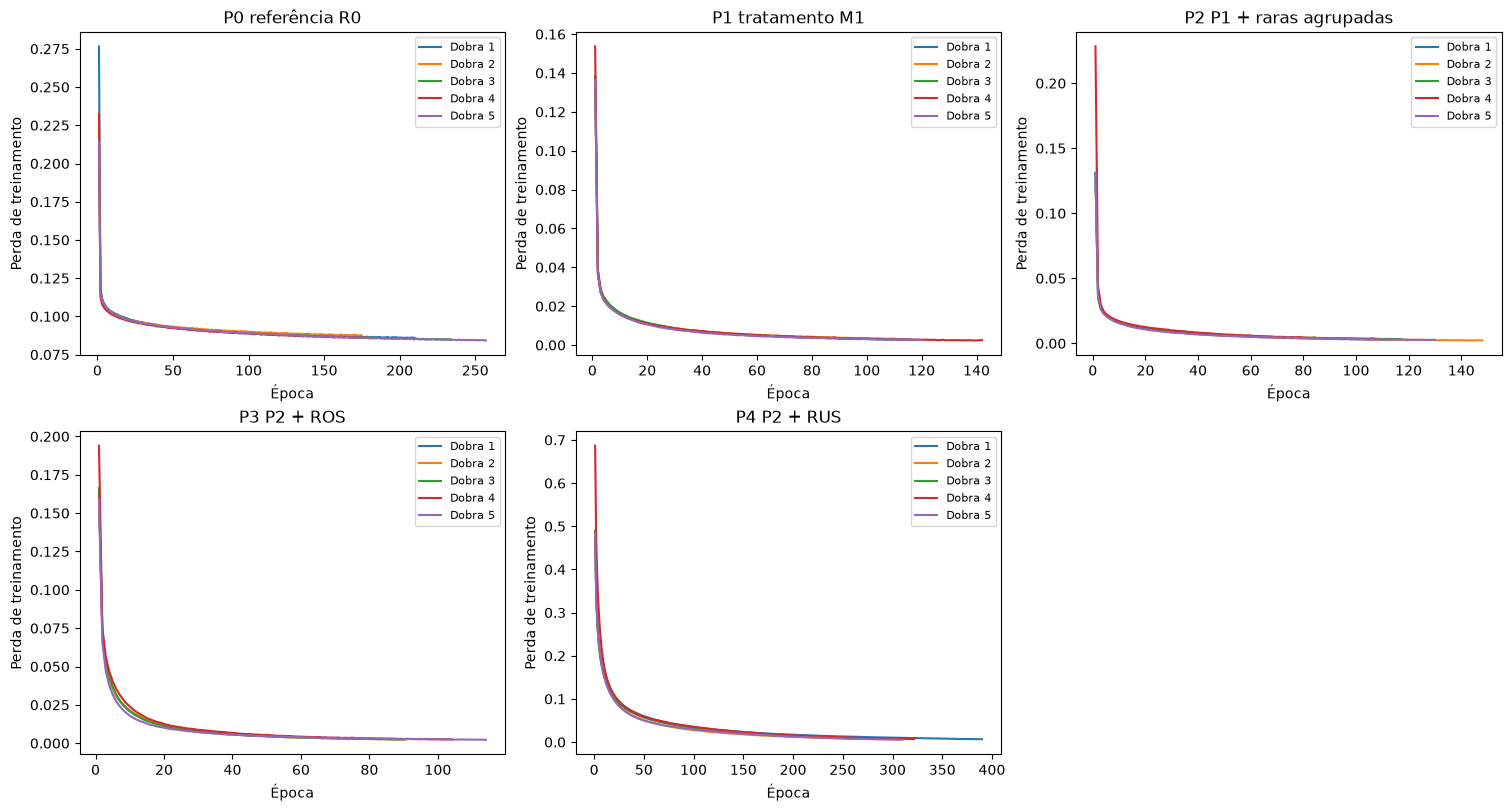

In [15]:
import matplotlib.pyplot as plt
fig, eixos = plt.subplots(2, 3, figsize=(15, 8), layout="constrained")
for eixo, nome_cfg in zip(eixos.flat, CONFIGURACOES):
    for historico in curvas_mlp_m3:
        if historico["configuracao"] == nome_cfg:
            perdas = historico["perdas"]
            eixo.plot(range(1, len(perdas) + 1), perdas, label=f"Dobra {historico['dobra']}")

    eixo.set_title(nome_cfg)
    eixo.set_xlabel("Época")
    eixo.set_ylabel("Perda de treinamento")
    eixo.legend(fontsize=8)

eixos.flat[-1].set_visible(False)
plt.show()


Todas as cinco configurações (`P0` a `P4`) apresentaram queda suave da perda de treinamento e terminaram com **zero `ConvergenceWarning`** após o aumento para `max_iter=400` e o pré-processamento com `log1p + StandardScaler`. O maior número de épocas ocorreu em `P4` (média `316,2`, máximo `390`, por ter menos amostras após o RUS) e em `P0` (média `214,4`, máximo `257`), enquanto `P1`, `P2` e `P3` convergiram entre `97,8` e `123,4` épocas em média. Como as perdas correspondem a conjuntos de treino diferentes entre combinações, a comparação de qualidade entre modelos deve usar exclusivamente as métricas de validação fora da dobra.


### 3.6 Seleção aninhada de hiperparâmetros da MLP (combinação P2)

Para manter paridade metodológica com a Árvore de Decisão e a Random Forest, executamos uma grade compacta de 4 configurações da MLP na combinação principal P2 (`log1p + StandardScaler`) por validação aninhada com 3 dobras internas por grupos: `hidden_layer_sizes` em `[(32,), (64, 32)]` e regularização L2 `alpha` em `[0,0001, 0,01]`.

In [16]:
# Seção 3 - 3.6 Seleção aninhada de hiperparâmetros da MLP (combinação principal P2, log1p + StandardScaler)
GRADE_MLP = [dict(hidden_layer_sizes=h, alpha=a)
             for h, a in product([(32,), (64, 32)], [1e-4, 1e-2])]

inicio = time.perf_counter()
with warnings.catch_warnings(record=True) as avisos_aninhada_mlp:
    warnings.simplefilter("always")
    por_dobra_aninhada_mlp, grade_interna_mlp = selecao_aninhada(
        modelo_mlp_m3, GRADE_MLP, "MLP (aninhada)", CONFIG_PRINCIPAL, escala="log1p_standard"
    )
conv_warns_mlp_nested = sum(issubclass(a.category, ConvergenceWarning) for a in avisos_aninhada_mlp)
print(f"Seleção aninhada da MLP concluída em {time.perf_counter() - inicio:.0f} s "
      f"(avisos de convergência: {conv_warns_mlp_nested}).")

with pd.option_context("display.float_format", "{:.4f}".format, "display.width", 250):
    display(por_dobra_aninhada_mlp[[
        "dobra", "param_hidden_layer_sizes", "param_alpha",
        "f1_macro_interno", "f1_macro", "f1_normal", "f1_anomaly", "FP", "FN"
    ]])
    mlp_fix_p2 = por_dobra_mlp[por_dobra_mlp.configuracao == CONFIG_PRINCIPAL].set_index("dobra").f1_macro
    print(f"F1-macro externo - MLP aninhada: {por_dobra_aninhada_mlp.f1_macro.mean():.4f} ± "
          f"{por_dobra_aninhada_mlp.f1_macro.std():.4f}; MLP fixada (P2, log1p+Std): "
          f"{mlp_fix_p2.mean():.4f} ± {mlp_fix_p2.std():.4f}")
    display(grade_interna_mlp.assign(hidden_layer_sizes=grade_interna_mlp.hidden_layer_sizes.map(rotulo))
            .pivot_table(index="hidden_layer_sizes", columns="alpha",
                         values="f1_macro_interno", aggfunc="mean"))

Seleção aninhada da MLP concluída em 191 s (avisos de convergência: 0).


,dobra,param_hidden_layer_sizes,param_alpha,f1_macro_interno,f1_macro,f1_normal,f1_anomaly,FP,FN
0,1,"(64, 32)",0.0001,0.8714,0.8727,0.9850,0.7605,206,189
1,2,"(64, 32)",0.01,0.8685,0.8762,0.9852,0.7671,211,177
2,3,"(32,)",0.01,0.8707,0.8759,0.9854,0.7664,198,186
3,4,"(64, 32)",0.0001,0.8710,0.8669,0.9844,0.7494,207,203
4,5,"(32,)",0.0001,0.8690,0.8710,0.9848,0.7572,206,193


F1-macro externo - MLP aninhada: 0.8725 ± 0.0038; MLP fixada (P2, log1p+Std): 0.8701 ± 0.0044


alpha,0.0001,0.0100
hidden_layer_sizes,,
"(32,)",0.8692,0.8691
"(64, 32)",0.8696,0.8689


### 3.7 Resultados e justificativa — Rede Neural (MLP)

**Efeito da escala e da transformação `log1p` em P2 (3.3).** A transformação não linear `log1p` antes da padronização resolveu a assimetria extrema das contagens de tráfego e superou `StandardScaler` puro nas 5 dobras:
- **Sem escala:** F1-macro `0,8225 ± 0,0107` (`F1 anomaly 0,6648`, perda média `0,1508`).
- **`StandardScaler`:** F1-macro `0,8677 ± 0,0049` (`F1 anomaly 0,7509`, perda média `0,0052`).
- **`log1p + StandardScaler`:** F1-macro **`0,8701 ± 0,0044`** (`F1 anomaly 0,7555`, perda média `0,0029`, 0 avisos de convergência).

**Comparação entre configurações P0–P4 com `log1p + StandardScaler` (3.4).**
- `P0 referência R0`: `0,8570 ± 0,0080` (`976 FP / 1.170 FN`)
- **`P1 tratamento M1`**: **`0,8722 ± 0,0041`** (`F1 anomaly 0,7595`, `1.031 FP / 950 FN`)
- `P2 P1 + raras agrupadas`: `0,8701 ± 0,0044` (`1.037 FP / 973 FN`)
- `P3 P2 + ROS`: `0,8686 ± 0,0028` (`1.162 FP / 914 FN`)
- `P4 P2 + RUS`: `0,8289 ± 0,0044` (`2.309 FP / 777 FN`)

Para a MLP com parâmetros fixos `(32,)`, o agrupamento de categorias raras (`P2`) perdeu ligeiramente para `P1` (`-0,0021`), enquanto ROS 1:1 e RUS 1:1 pioraram a precisão de `anomaly` (`0,7315` e `0,5885`). Todas as 25 execuções terminaram com 0 `ConvergenceWarning`.

**Seleção aninhada em P2 (3.6).** Na grade de 4 combinações (`hidden_layer_sizes` em `[(32,), (64, 32)]` e `alpha` em `[0,0001, 0,01]`), a validação aninhada selecionou `(64, 32)` em 3 dobras (dobras 1, 2 e 4) e `(32,)` em 2 dobras (dobras 3 e 5), com 0 avisos de convergência. Isso elevou o F1-macro externo da MLP em P2 de `0,8701 ± 0,0044` para **`0,8725 ± 0,0038`** (`F1 anomaly = 0,7601`, `1.028 FP / 948 FN`), superando também `P1` fixada (`0,8722`) e mantendo paridade metodológica na comparação com Árvore e Random Forest.


## 4. Tabela comparativa estruturada

**Objetivo:** Reunir os resultados dos três algoritmos (Árvore de Decisão, Random Forest e MLP), conferir a comparabilidade das dobras e gerar tabela consolidada e gráficos de F1-macro médio/desvio, precisão, recall, F1 por classe e tempo; a acurácia é apresentada como complementar.

**Entregável:** Tabela pré-processamento x balanceamento x algoritmo x métricas, com discussão dos ganhos, perdas e limitações.


### 4.1 Consolidação e verificação de comparabilidade

Reunimos os resultados dos três algoritmos (Árvore de Decisão, Random Forest e MLP). A tabela principal apresenta 15 linhas, comparando os três modelos nas cinco combinações (P0 a P4), com a média e desvio entre as cinco dobras. As variantes complementares são listadas separadamente: seleção aninhada dos três algoritmos (incluindo o ajuste interno de limiar da Random Forest) em P2 e as escalas alternativas da MLP (`StandardScaler` puro e sem escala) em P2.

Verificamos automaticamente que todas as avaliações usaram exatamente as mesmas divisões de treino e validação, com a mesma quantidade de registros e anomalias na validação e o mesmo treino filtrado em cada combinação e dobra.


In [17]:
# Seção 4 - 4.1 Tabela comparativa: consolidação dos três algoritmos e verificações de comparabilidade
DESCRICAO_PREP = {
    "P0 referência R0": "R0: categorias brutas, fora do domínio mantido, todas as colunas e linhas, One-Hot",
    "P1 tratamento M1": "M1: categorias normalizadas, fora do domínio -> ausente, sem derivadas/constantes, "
                        "treino sem conflitos, One-Hot",
    "P2 P1 + raras agrupadas": "M1 + One-Hot com categorias raras agrupadas",
    "P3 P2 + ROS": "M1 + One-Hot com categorias raras agrupadas",
    "P4 P2 + RUS": "M1 + One-Hot com categorias raras agrupadas",
}
NOME_BALANCEAMENTO = {None: "nenhum", "ROS": "RandomOverSampler 1:1", "RUS": "RandomUnderSampler 1:1"}
ORDEM_ALGORITMOS = ["Árvore de Decisão", "Random Forest", "MLP"]
COLS_DOBRA = ["configuracao", "dobra", "f1_macro", "acuracia", "TN", "FP", "FN", "TP",
              *[f"{m}_{c}" for c in CLASSES for m in ("precisao", "recall", "f1")],
              "n_treino_ajuste", "segundos_ajuste", "segundos_predicao"]
# (algoritmo, variante, escala, resultados por dobra, linha principal?, sufixo do rótulo curto)
FONTES_ETAPA3 = [
    ("Árvore de Decisão", "parâmetros padrão", "nenhuma", por_dobra_arvore, True, "Árvore"),
    ("Random Forest", "parâmetros fixados", "nenhuma", por_dobra_rf, True, "RF"),
    ("MLP", "parâmetros fixados", "log1p + StandardScaler", por_dobra_mlp, True, "MLP"),
    ("Árvore de Decisão", "seleção aninhada", "nenhuma", por_dobra_aninhada, False, "Árvore aninhada"),
    ("Random Forest", "seleção aninhada", "nenhuma", por_dobra_aninhada_rf, False, "RF aninhada"),
    ("Random Forest", "seleção aninhada + limiar", "nenhuma", por_dobra_aninhada_rf_limiar, False, "RF aninhada + limiar"),
    ("MLP", "seleção aninhada", "log1p + StandardScaler", por_dobra_aninhada_mlp, False, "MLP aninhada"),
    ("MLP", "parâmetros fixados", "StandardScaler",
     por_dobra_escala_m3[por_dobra_escala_m3.escala == "StandardScaler"], False, "MLP StandardScaler"),
    ("MLP", "parâmetros fixados", "nenhuma",
     por_dobra_escala_m3[por_dobra_escala_m3.escala == "Sem escala"], False, "MLP sem escala"),
]
por_dobra_etapa3 = pd.concat([
    df[COLS_DOBRA].assign(algoritmo=alg, variante=var, escala=esc, principal=princ,
                          rotulo=lambda d, curto=curto: curto + " · " + d.configuracao.str.split().str[0])
    for alg, var, esc, df, princ, curto in FONTES_ETAPA3], ignore_index=True)

# 1) Cada candidato tem as cinco dobras comuns, uma vez cada.
assert por_dobra_etapa3.groupby("rotulo").dobra.apply(sorted).map(lambda d: d == list(range(1, N_DOBRAS + 1))).all()
# 2) Validação intacta e idêntica para todos: mesmo total e mesmas anomalias em cada dobra.
tamanho_validacao = {d: len(iva) for d, (_, iva) in enumerate(INDICES_DOBRAS, start=1)}
anomalias_validacao = {d: int(y_treino.iloc[iva].sum()) for d, (_, iva) in enumerate(INDICES_DOBRAS, start=1)}
assert (por_dobra_etapa3[["TN", "FP", "FN", "TP"]].sum(axis=1) == por_dobra_etapa3.dobra.map(tamanho_validacao)).all()
assert (por_dobra_etapa3.TP + por_dobra_etapa3.FN == por_dobra_etapa3.dobra.map(anomalias_validacao)).all()
# 3) Tabela principal completa e com o mesmo treino filtrado para os três algoritmos.
principal_dobras = por_dobra_etapa3[por_dobra_etapa3.principal]
assert len(principal_dobras) == 3 * len(CONFIGURACOES) * N_DOBRAS
assert por_dobra_etapa3.groupby(["configuracao", "dobra"]).n_treino_ajuste.nunique().eq(1).all()
print(f"{por_dobra_etapa3.rotulo.nunique()} candidatos x {N_DOBRAS} dobras verificados: mesmas dobras, "
      "validação intacta e mesmo treino filtrado.")


def consolidar(por_dobra):
    """Média ± dp entre dobras por candidato (métricas por classe, acurácia, erros somados e tempos)."""
    metricas = [f"{m}_{c}" for c in CLASSES for m in ("precisao", "recall", "f1")]
    return (por_dobra.groupby(["rotulo", "algoritmo", "variante", "escala", "configuracao", "principal"], sort=False)
            .agg(f1_macro_media=("f1_macro", "mean"), f1_macro_dp=("f1_macro", "std"),
                 **{m: (m, "mean") for m in metricas}, acuracia=("acuracia", "mean"),
                 FP=("FP", "sum"), FN=("FN", "sum"),
                 seg_ajuste=("segundos_ajuste", "mean"), seg_predicao=("segundos_predicao", "mean"))
            .reset_index())


tabela_etapa3 = consolidar(por_dobra_etapa3)
tabela_etapa3["pre_processamento"] = tabela_etapa3.configuracao.map(DESCRICAO_PREP)
tabela_etapa3["balanceamento"] = tabela_etapa3.configuracao.map(
    lambda n: NOME_BALANCEAMENTO[CONFIGURACOES[n]["balanceamento"]])

# Formato da tabela do relatório: pré-processamento x balanceamento x algoritmo x métricas.
par = lambda a, b: f"{a:.4f} / {b:.4f}"
sufixo_alg = np.where(
    tabela_etapa3.variante.str.startswith("seleção "),
    " (" + tabela_etapa3.variante.str.replace("seleção ", "", regex=False) + ")",
    "",
)
tabela_relatorio = pd.DataFrame({
    "Combinação": tabela_etapa3.configuracao.str.split().str[0],
    "Pré-processamento": tabela_etapa3.pre_processamento,
    "Escala": tabela_etapa3.escala,
    "Balanceamento": tabela_etapa3.balanceamento,
    "Algoritmo": tabela_etapa3.algoritmo + sufixo_alg,
    "F1-macro (média ± dp)": [f"{m:.4f} ± {d:.4f}" for m, d in zip(tabela_etapa3.f1_macro_media, tabela_etapa3.f1_macro_dp)],
    "Precisão normal / anomaly": [par(a, b) for a, b in zip(tabela_etapa3.precisao_normal, tabela_etapa3.precisao_anomaly)],
    "Recall normal / anomaly": [par(a, b) for a, b in zip(tabela_etapa3.recall_normal, tabela_etapa3.recall_anomaly)],
    "F1 normal / anomaly": [par(a, b) for a, b in zip(tabela_etapa3.f1_normal, tabela_etapa3.f1_anomaly)],
    "Acurácia": tabela_etapa3.acuracia.round(4),
    "FP / FN (soma)": tabela_etapa3.FP.astype(str) + " / " + tabela_etapa3.FN.astype(str),
    "Ajuste (s/dobra)": tabela_etapa3.seg_ajuste.round(2),
    "Predição (s/dobra)": tabela_etapa3.seg_predicao.round(3),
})
ordem_principal = (tabela_etapa3[tabela_etapa3.principal]
                   .assign(o_cfg=lambda d: d.configuracao.map({n: i for i, n in enumerate(CONFIGURACOES)}),
                           o_alg=lambda d: d.algoritmo.map(ORDEM_ALGORITMOS.index))
                   .sort_values(["o_cfg", "o_alg"]).index)
with pd.option_context("display.max_columns", None, "display.width", 300, "display.max_colwidth", 60):
    print("Tabela principal - 3 algoritmos x 5 combinações (mesmas 5 dobras):")
    display(tabela_relatorio.loc[ordem_principal].reset_index(drop=True))
    print("Variantes complementares (combinação P2):")
    display(tabela_relatorio[~tabela_etapa3.principal].reset_index(drop=True))

# F1-macro médio por combinação x algoritmo e algoritmo com maior F1-macro em cada dobra.
f1_principal = principal_dobras.pivot_table(index="configuracao", columns="algoritmo", values="f1_macro",
                                            aggfunc="mean").reindex(index=CONFIGURACOES, columns=ORDEM_ALGORITMOS)
vencedor_dobra = (principal_dobras.loc[principal_dobras.groupby(["configuracao", "dobra"]).f1_macro.idxmax()]
                  .groupby("configuracao").algoritmo.value_counts().unstack(fill_value=0)
                  .reindex(index=CONFIGURACOES, columns=ORDEM_ALGORITMOS, fill_value=0))
print("F1-macro médio (combinação x algoritmo) e número de dobras em que cada algoritmo foi o melhor:")
display(f1_principal.round(4).join(vencedor_dobra.add_prefix("dobras_melhor_")))


21 candidatos x 5 dobras verificados: mesmas dobras, validação intacta e mesmo treino filtrado.
Tabela principal - 3 algoritmos x 5 combinações (mesmas 5 dobras):


,Combinação,Pré-processamento,Escala,Balanceamento,Algoritmo,F1-macro (média ± dp),Precisão normal / anomaly,Recall normal / anomaly,F1 normal / anomaly,Acurácia,FP / FN (soma),Ajuste (s/dobra),Predição (s/dobra)
0,P0,"R0: categorias brutas, fora do domínio mantido, todas as...",nenhuma,nenhum,Árvore de Decisão,0.8050 ± 0.0056,0.9726 / 0.7341,0.9876 / 0.5519,0.9800 / 0.6299,0.9621,816 / 1828,1.09,0.011
1,P0,"R0: categorias brutas, fora do domínio mantido, todas as...",nenhuma,nenhum,Random Forest,0.8733 ± 0.0049,0.9849 / 0.7658,0.9856 / 0.7568,0.9853 / 0.7612,0.9723,944 / 992,1.63,0.061
2,P0,"R0: categorias brutas, fora do domínio mantido, todas as...",log1p + StandardScaler,nenhum,MLP,0.8570 ± 0.0080,0.9823 / 0.7487,0.9852 / 0.7132,0.9837 / 0.7303,0.9693,976 / 1170,8.97,0.015
3,P1,"M1: categorias normalizadas, fora do domínio -> ausente,...",nenhuma,nenhum,Árvore de Decisão,0.8706 ± 0.0044,0.9859 / 0.7407,0.9832 / 0.7735,0.9846 / 0.7566,0.9709,1105 / 924,0.60,0.017
4,P1,"M1: categorias normalizadas, fora do domínio -> ausente,...",nenhuma,nenhum,Random Forest,0.8746 ± 0.0049,0.9853 / 0.7651,0.9855 / 0.7627,0.9854 / 0.7639,0.9725,955 / 968,0.88,0.044
5,P1,"M1: categorias normalizadas, fora do domínio -> ausente,...",log1p + StandardScaler,nenhum,MLP,0.8722 ± 0.0041,0.9855 / 0.7522,0.9843 / 0.7671,0.9849 / 0.7595,0.9716,1031 / 950,4.36,0.022
6,P2,M1 + One-Hot com categorias raras agrupadas,nenhuma,nenhum,Árvore de Decisão,0.8730 ± 0.0038,0.9863 / 0.7434,0.9833 / 0.7801,0.9848 / 0.7612,0.9714,1099 / 897,0.41,0.016
7,P2,M1 + One-Hot com categorias raras agrupadas,nenhuma,nenhum,Random Forest,0.8756 ± 0.0051,0.9856 / 0.7643,0.9853 / 0.7673,0.9854 / 0.7658,0.9726,965 / 949,0.89,0.046
8,P2,M1 + One-Hot com categorias raras agrupadas,log1p + StandardScaler,nenhum,MLP,0.8701 ± 0.0044,0.9852 / 0.7497,0.9842 / 0.7615,0.9847 / 0.7555,0.9712,1037 / 973,3.78,0.021
9,P3,M1 + One-Hot com categorias raras agrupadas,nenhuma,RandomOverSampler 1:1,Árvore de Decisão,0.8630 ± 0.0045,0.9844 / 0.7356,0.9833 / 0.7490,0.9839 / 0.7422,0.9696,1098 / 1024,0.40,0.016


Variantes complementares (combinação P2):


,Combinação,Pré-processamento,Escala,Balanceamento,Algoritmo,F1-macro (média ± dp),Precisão normal / anomaly,Recall normal / anomaly,F1 normal / anomaly,Acurácia,FP / FN (soma),Ajuste (s/dobra),Predição (s/dobra)
0,P2,M1 + One-Hot com categorias raras agrupadas,nenhuma,nenhum,Árvore de Decisão (aninhada),0.8725 ± 0.0043,0.9862 / 0.7430,0.9833 / 0.7786,0.9848 / 0.7603,0.9713,1099 / 903,0.42,0.017
1,P2,M1 + One-Hot com categorias raras agrupadas,nenhuma,nenhum,Random Forest (aninhada),0.8800 ± 0.0022,0.9867 / 0.7627,0.9848 / 0.7862,0.9858 / 0.7743,0.9732,998 / 872,1.73,0.043
2,P2,M1 + One-Hot com categorias raras agrupadas,nenhuma,nenhum,Random Forest (aninhada + limiar),0.8818 ± 0.0007,0.9876 / 0.7560,0.9840 / 0.8009,0.9858 / 0.7778,0.9733,1055 / 812,1.73,0.043
3,P2,M1 + One-Hot com categorias raras agrupadas,log1p + StandardScaler,nenhum,MLP (aninhada),0.8725 ± 0.0038,0.9856 / 0.7528,0.9844 / 0.7676,0.9850 / 0.7601,0.9717,1028 / 948,4.45,0.020
4,P2,M1 + One-Hot com categorias raras agrupadas,StandardScaler,nenhum,MLP,0.8677 ± 0.0049,0.9847 / 0.7482,0.9843 / 0.7539,0.9845 / 0.7509,0.9708,1035 / 1004,3.72,0.018
5,P2,M1 + One-Hot com categorias raras agrupadas,nenhuma,nenhum,MLP,0.8225 ± 0.0107,0.9775 / 0.6995,0.9830 / 0.6347,0.9802 / 0.6648,0.9626,1120 / 1490,1.17,0.017


F1-macro médio (combinação x algoritmo) e número de dobras em que cada algoritmo foi o melhor:


algoritmo,Árvore de Decisão,Random Forest,MLP,dobras_melhor_Árvore de Decisão,dobras_melhor_Random Forest,dobras_melhor_MLP
configuracao,,,,,,
P0 referência R0,0.8050,0.8733,0.8570,0,5,0
P1 tratamento M1,0.8706,0.8746,0.8722,0,4,1
P2 P1 + raras agrupadas,0.8730,0.8756,0.8701,0,5,0
P3 P2 + ROS,0.8630,0.8779,0.8686,0,5,0
P4 P2 + RUS,0.7973,0.8516,0.8289,0,5,0


### 4.2 Gráficos comparativos

Cada painel mostra uma métrica por combinação (eixo horizontal) e algoritmo (cor e marcador). Usamos pontos em vez de barras porque as diferenças estão concentradas em uma faixa estreita: barras precisariam começar no zero e esconderiam as diferenças. O F1-macro traz a barra de ±1 desvio-padrão entre dobras. O tempo de ajuste está em escala logarítmica e é tempo de relógio: a Random Forest usa todos os núcleos (seção 2.5). As cores formam uma paleta validada para daltonismo, e o marcador repete a identidade do algoritmo.

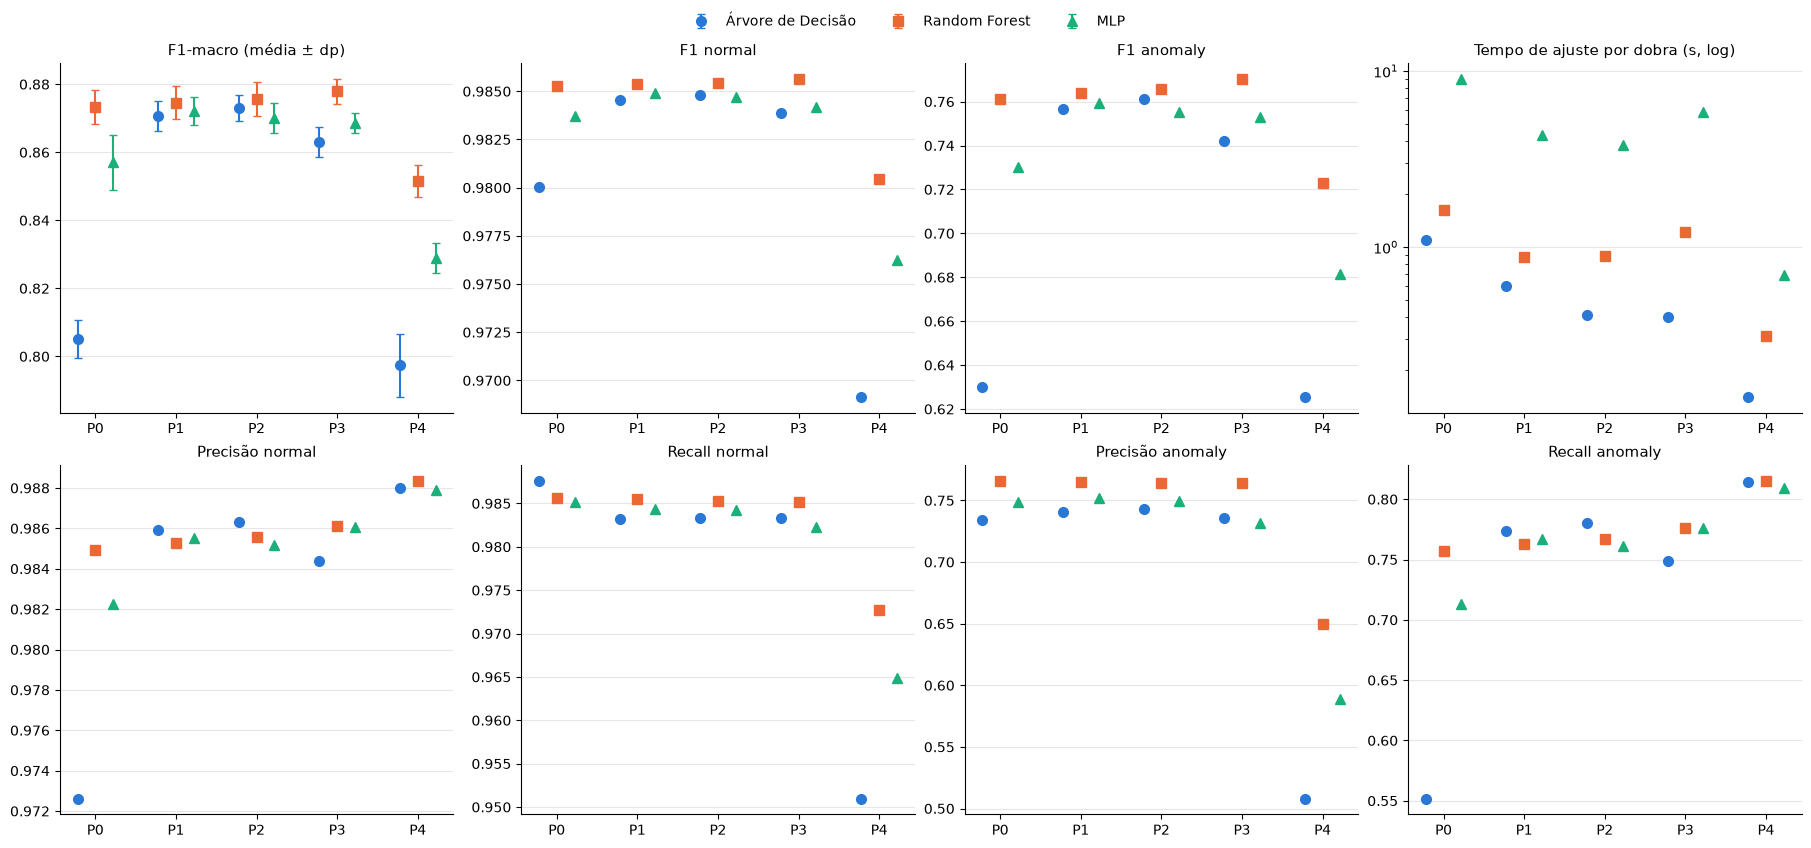

In [18]:
# Seção 4 - 4.2 Gráficos: F1-macro (média ± dp), precisão, recall e F1 por classe e tempo de ajuste
import matplotlib.pyplot as plt

# Paleta categórica validada para daltonismo (Delta E >= 8 entre pares); o marcador é a codificação secundária.
CORES_ALGORITMO = {"Árvore de Decisão": "#2a78d6", "Random Forest": "#eb6834", "MLP": "#1baf7a"}
MARCADORES_ALGORITMO = {"Árvore de Decisão": "o", "Random Forest": "s", "MLP": "^"}
PAINEIS = [("f1_macro_media", "F1-macro (média ± dp)"), ("f1_normal", "F1 normal"), ("f1_anomaly", "F1 anomaly"),
           ("seg_ajuste", "Tempo de ajuste por dobra (s, log)"),
           ("precisao_normal", "Precisão normal"), ("recall_normal", "Recall normal"),
           ("precisao_anomaly", "Precisão anomaly"), ("recall_anomaly", "Recall anomaly")]
tabela_principal = tabela_etapa3[tabela_etapa3.principal]
posicoes = np.arange(len(CONFIGURACOES))

fig, eixos = plt.subplots(2, 4, figsize=(18, 8.4), layout="constrained")
for eixo, (coluna, titulo) in zip(eixos.flat, PAINEIS):
    for j, (algoritmo, cor) in enumerate(CORES_ALGORITMO.items()):
        dados = tabela_principal[tabela_principal.algoritmo == algoritmo].set_index("configuracao").reindex(CONFIGURACOES)
        eixo.errorbar(posicoes + (j - 1) * 0.22, dados[coluna],
                      yerr=dados.f1_macro_dp if coluna == "f1_macro_media" else None,
                      fmt=MARCADORES_ALGORITMO[algoritmo], color=cor, markersize=7, capsize=3, elinewidth=1.5,
                      linestyle="none", label=algoritmo)
    eixo.set_xticks(posicoes, [n.split()[0] for n in CONFIGURACOES])
    eixo.set_title(titulo, fontsize=11)
    eixo.grid(axis="y", color="#e6e6e6", linewidth=0.8)
    eixo.set_axisbelow(True)
    eixo.spines[["top", "right"]].set_visible(False)
    if coluna == "seg_ajuste":
        eixo.set_yscale("log")
fig.legend(*eixos.flat[0].get_legend_handles_labels(), loc="outside upper center", ncol=3, frameon=False)
plt.show()


### Resultados e justificativa — Seção 4 (Tabela comparativa)

**Comparabilidade.** As `105` avaliações (`21` candidatos x `5` dobras) passaram em todas as checagens da seção 4.1:
- mesmas 5 dobras por grupos (`ASSINATURA_DOBRAS = 8a814c72d149c698`);
- mesma validação intacta em cada dobra (`13.966–13.968` linhas e `815–816` anomalias);
- mesmo treino filtrado em cada combinação e dobra para todos os algoritmos.

**Tabela principal.** F1-macro médio ± desvio nas 5 dobras; o melhor resultado de cada algoritmo está em negrito:

| Combinação | Balanceamento | Árvore de Decisão | Random Forest | MLP (`log1p + StandardScaler`) |
|---|---|---:|---:|---:|
| P0 (R0) | nenhum | 0,8050 ± 0,0056 | 0,8733 ± 0,0049 | 0,8570 ± 0,0080 |
| P1 (M1) | nenhum | 0,8706 ± 0,0044 | 0,8746 ± 0,0049 | **0,8722 ± 0,0041** |
| P2 (M1 + raras agrupadas) | nenhum | **0,8730 ± 0,0038** | 0,8756 ± 0,0051 | 0,8701 ± 0,0044 |
| P3 (P2) | ROS 1:1 | 0,8630 ± 0,0045 | **0,8779 ± 0,0036** | 0,8686 ± 0,0028 |
| P4 (P2) | RUS 1:1 | 0,7973 ± 0,0092 | 0,8516 ± 0,0048 | 0,8289 ± 0,0044 |

**Variantes complementares em P2:**
- `Árvore de Decisão (aninhada)`: `0,8725 ± 0,0043`
- `Random Forest (aninhada)`: `0,8800 ± 0,0022`
- **`Random Forest (aninhada + limiar)`**: **`0,8818 ± 0,0007`**
- `MLP (aninhada)`: **`0,8725 ± 0,0038`**
- `MLP StandardScaler`: `0,8677 ± 0,0049`
- `MLP sem escala`: `0,8225 ± 0,0107`

A tabela detalhada (com precisão, recall e F1 por classe, acurácia, FP/FN e tempos médios por dobra) está impressa na saída de 4.1, exatamente no formato exigido para o relatório final.

**Ganhos e interação pré-processamento x algoritmo.**
- **Random Forest é superior em todas as combinações:** lidera as médias de `P0` a `P4` e vence `24 de 25` comparações pareadas por dobra na tabela principal (MLP venceu apenas a dobra 1 em `P1`). Entre os candidatos com seleção aninhada em P2, `Random Forest (aninhada + limiar)` atinge `0,8818 ± 0,0007` (com `precisão / recall anomaly` = `0,7560 / 0,8009`, `F1 anomaly = 0,7778`), contra `0,8730` da melhor Árvore (`P2`) e `0,8725` da melhor MLP (`aninhada`).
- **A classe `normal` satura em `F1` (`0,984–0,986` em P1–P3):** quase todo ganho real aparece na classe `anomaly`.
- **Limpeza M1 (P0 → P1):** decisiva para a Árvore (`+0,0656`), importante para a MLP (`+0,0152`) e moderada para a Random Forest (`+0,0013`).
- **Agrupamento de raras (P1 → P2):** ajuda Árvore (`+0,0024`) e RF (`+0,0010`), reduzindo dimensionalidade e tempo; na MLP fixada cai `-0,0021`, mas com seleção aninhada em P2 a MLP alcança `0,8725`.
- **Balanceamento extremo 1:1:** RUS derruba os três modelos pela explosão de falsos positivos (`1.797–3.223 FP`); ROS 1:1 ajuda apenas a RF base (`0,8779`), mas fica atrás de pesos moderados e ajuste de limiar na RF aninhada (`0,8800` / `0,8818`).

**Custo computacional (14 núcleos).** Tempos médios de ajuste por dobra na máquina de execução: Árvore `0,14–1,09 s`, Random Forest `0,31–1,73 s` (com `n_jobs=-1`), MLP `0,69–8,97 s`; tempos de predição abaixo de `0,07 s/dobra` para todos. A acurácia (`0,943–0,973`) mascara diferenças expressivas na classe minoritária e permanece apenas como métrica complementar.

**Limitações.** As combinações P0–P4 reutilizam as dobras da etapa 2, introduzindo potencial otimismo acumulado; os tempos dependem de hardware e paralelismo; e os sinais operacionais seguem excluídos preventivamente.


## 5. Seleção do vencedor e auditoria metodológica

**Objetivo:** Auditar a execução dos pipelines, aplicar regra determinística de seleção do vencedor por validação interna (priorizando F1-macro), verificar estabilidade em uma segunda divisão (semente 137), estimar otimismo de seleção e gerar configuração integralmente reproduzível para a Etapa 4.

**Entregável:** Justificativa do vencedor e dicionário/fábrica reproduzíveis para a Etapa 4, sem nenhuma decisão guiada pelo teste oficial.


### 5.1 Critério determinístico de seleção

A regra de escolha do vencedor é estritamente determinística e independente de hardware (não utiliza tempo de relógio, que pode inverter vencedores conforme o número de núcleos da máquina):

1. Maior **F1-macro médio** nas cinco dobras (diferença inferior a `0,0005` em relação ao líder conta como empate prático);
2. Entre os empatados, maior **F1 médio da classe `anomaly`** (com o mesmo limiar de empate `0,0005`);
3. Persistindo o empate, **maior número de vitórias pareadas dobra a dobra** contra os demais candidatos ainda empatados;
4. Persistindo o empate, **menor desvio-padrão de F1-macro** entre dobras, preferência por pipeline sem reamostragem (mais simples) e ordem lexicográfica do rótulo.

### 5.2 Auditoria dos pipelines

Antes da seleção, auditamos os dados em memória (`sha256` de `treino.csv`), os 46 preditores (ausência de `id`, `class` e dos três sinais operacionais), a integridade das dobras, a validação intacta em todas as avaliações, o ajuste restrito ao treino na dobra 1 e a ausência de citações aos arquivos de teste ou submissão nas células executadas.


In [19]:
# Seção 5 - 5.2 Auditoria metodológica dos pipelines (sem consultar o teste oficial)
import json
import matplotlib

verificacoes = {}

# Dados: impressão digital do arquivo; nenhuma seção alterou X_treino/y_treino em memória.
HASH_TREINO = hashlib.sha256((DIR_DADOS / "treino.csv").read_bytes()).hexdigest()
X_conferencia, y_conferencia = carregar_treino()
assert X_conferencia.equals(X_treino) and y_conferencia.equals(y_treino)
verificacoes["Dados: sha256 de treino.csv; objetos em memória iguais ao arquivo"] = HASH_TREINO[:16]

# Preditores: sem id, rótulo e sinais operacionais.
assert not set(SINAIS_OPERACIONAIS + [COL_ID, COL_ROTULO]).intersection(X_treino.columns)
verificacoes["Preditores: sem id, class e sinais operacionais"] = f"{X_treino.shape[1]} atributos"

# Dobras: mesma assinatura da Seção 1, partição completa e grupos disjuntos.
dobra_auditada = np.zeros(len(X_treino), dtype=int)
for i, (itr, iva) in enumerate(INDICES_DOBRAS, start=1):
    assert not np.intersect1d(itr, iva).size and len(itr) + len(iva) == len(X_treino)
    assert set(grupos_treino.iloc[itr]).isdisjoint(grupos_treino.iloc[iva])
    dobra_auditada[iva] = i
assert (dobra_auditada > 0).all()
assert hashlib.sha256(dobra_auditada.tobytes()).hexdigest()[:16] == ASSINATURA_DOBRAS
verificacoes["Dobras: mesma assinatura, partição completa, grupos disjuntos"] = ASSINATURA_DOBRAS

# Validação intacta em todos os candidatos (exigida na Seção 4 e refeita sobre a tabela final).
assert (por_dobra_etapa3[["TN", "FP", "FN", "TP"]].sum(axis=1) == por_dobra_etapa3.dobra.map(tamanho_validacao)).all()
verificacoes["Validação: todas as linhas, sem filtro nem reamostragem"] = f"{len(por_dobra_etapa3)} avaliações conferidas"

# Ajuste só no treino da dobra 1: o filtro remove apenas linhas do treino; as medianas do imputador são
# as do treino filtrado; o modelo recebe o treino reamostrado e a validação é prevista inteira.
itr, iva = INDICES_DOBRAS[0]
for nome_cfg, cfg in CONFIGURACOES.items():
    X_fit, y_fit = filtrar_linhas_treino(X_treino.iloc[itr], y_treino.iloc[itr], cfg["linhas_treino"])
    assert set(X_fit.index) <= set(X_treino.index[itr]) and not set(X_fit.index) & set(X_treino.index[iva])
    assert len(X_fit) == por_dobra_etapa3[(por_dobra_etapa3.configuracao == nome_cfg)
                                          & (por_dobra_etapa3.dobra == 1)].n_treino_ajuste.iloc[0]
    pipe = montar_pipeline(cfg, ARVORE_PADRAO).fit(X_fit, y_fit)
    imp = pipe.named_steps["imputacao_codificacao"].named_transformers_["num"].named_steps["imp"]
    np.testing.assert_allclose(imp.statistics_, pipe[:3].transform(X_fit)[imp.feature_names_in_].median().to_numpy())
    n_normal, n_anomaly = int((y_fit == 0).sum()), int((y_fit == 1).sum())
    esperado = {None: n_normal + n_anomaly, "ROS": 2 * n_normal, "RUS": 2 * n_anomaly}[cfg["balanceamento"]]
    assert pipe.named_steps["modelo"].tree_.n_node_samples[0] == esperado      # linhas que chegaram ao modelo
    assert len(pipe.predict(X_treino.iloc[iva])) == len(iva)
verificacoes["Ajuste só no treino: filtro, medianas e reamostragem (P0–P4, dobra 1)"] = "conferido"

# Teste oficial: nenhuma célula executada até aqui cita os arquivos de teste ou de submissão.
historico = globals().get("In", [])
alvos = ["teste_sem" + "_rotulo", "modelo_de" + "_submissao"]    # montados por partes para não casar com esta célula
assert len(historico) > 1 and not any(a in celula for celula in historico for a in alvos)
verificacoes["Teste oficial: nenhuma célula executada cita os arquivos de teste"] = f"{len(historico) - 1} células"

VERSOES = {"Python": platform.python_version(), "numpy": np.__version__, "pandas": pd.__version__,
           "scikit-learn": sklearn.__version__, "imbalanced-learn": imblearn.__version__,
           "matplotlib": matplotlib.__version__}
verificacoes["Sementes: dobras, amostradores e modelos"] = SEMENTE
verificacoes["Versões"] = ", ".join(f"{k} {v}" for k, v in VERSOES.items())
with pd.option_context("display.max_colwidth", 120):
    display(pd.Series(verificacoes, name="resultado").to_frame())


,resultado
Dados: sha256 de treino.csv; objetos em memória iguais ao arquivo,9713c75938ef1e9e
"Preditores: sem id, class e sinais operacionais",46 atributos
"Dobras: mesma assinatura, partição completa, grupos disjuntos",8a814c72d149c698
"Validação: todas as linhas, sem filtro nem reamostragem",105 avaliações conferidas
"Ajuste só no treino: filtro, medianas e reamostragem (P0–P4, dobra 1)",conferido
Teste oficial: nenhuma célula executada cita os arquivos de teste,19 células
"Sementes: dobras, amostradores e modelos",42
Versões,"Python 3.13.14, numpy 2.5.2, pandas 3.0.5, scikit-learn 1.9.0, imbalanced-learn 0.14.2, matplotlib 3.11.1"


### 5.3 Aplicação da regra determinística de seleção

A regra da seção 5.1 é aplicada à tabela consolidada da Seção 4; em seguida, comparamos o vencedor com cada um dos demais candidatos dobra a dobra (diferença média, mínima, máxima e contagem de vitórias pareadas).


Empatados com o líder no F1-macro (diferença < 0,0005): ['RF aninhada + limiar · P2']
Vencedor: RF aninhada + limiar · P2 - Random Forest (seleção aninhada + limiar, escala nenhuma), P2 P1 + raras agrupadas: F1-macro 0.8818 ± 0.0007


,rotulo,algoritmo,variante,escala,configuracao,f1_macro_media,f1_macro_dp,dif_para_lider,f1_anomaly,precisao_anomaly,recall_anomaly,seg_ajuste
1,RF aninhada + limiar · P2,Random Forest,seleção aninhada + limiar,nenhuma,P2 P1 + raras agrupadas,0.8818,0.0007,0.0000,0.7778,0.7560,0.8009,1.7310
2,RF aninhada · P2,Random Forest,seleção aninhada,nenhuma,P2 P1 + raras agrupadas,0.8800,0.0022,-0.0018,0.7743,0.7627,0.7862,1.7310
3,RF · P3,Random Forest,parâmetros fixados,nenhuma,P3 P2 + ROS,0.8779,0.0036,-0.0039,0.7702,0.7641,0.7764,1.2214
4,RF · P2,Random Forest,parâmetros fixados,nenhuma,P2 P1 + raras agrupadas,0.8756,0.0051,-0.0061,0.7658,0.7643,0.7673,0.8939
5,RF · P1,Random Forest,parâmetros fixados,nenhuma,P1 tratamento M1,0.8746,0.0049,-0.0072,0.7639,0.7651,0.7627,0.8763
6,RF · P0,Random Forest,parâmetros fixados,nenhuma,P0 referência R0,0.8733,0.0049,-0.0085,0.7612,0.7658,0.7568,1.6313
7,Árvore · P2,Árvore de Decisão,parâmetros padrão,nenhuma,P2 P1 + raras agrupadas,0.8730,0.0038,-0.0088,0.7612,0.7434,0.7801,0.4115
8,MLP aninhada · P2,MLP,seleção aninhada,log1p + StandardScaler,P2 P1 + raras agrupadas,0.8725,0.0038,-0.0092,0.7601,0.7528,0.7676,4.4462
9,Árvore aninhada · P2,Árvore de Decisão,seleção aninhada,nenhuma,P2 P1 + raras agrupadas,0.8725,0.0043,-0.0092,0.7603,0.7430,0.7786,0.4217
10,MLP · P1,MLP,parâmetros fixados,log1p + StandardScaler,P1 tratamento M1,0.8722,0.0041,-0.0096,0.7595,0.7522,0.7671,4.3573


Vencedor (RF aninhada + limiar · P2) - cada candidato, por dobra (5 dobras):


,dif_media,dif_min,dif_max,dobras_vencedor_melhor
rotulo,,,,
RF aninhada · P2,0.0018,-0.0005,0.0042,4
RF · P3,0.0039,0.0002,0.0081,5
RF · P2,0.0061,0.0005,0.0116,5
RF · P1,0.0072,0.0018,0.0129,5
RF · P0,0.0085,0.0034,0.0147,5
Árvore · P2,0.0088,0.0041,0.0123,5
MLP aninhada · P2,0.0092,0.0052,0.0146,5
Árvore aninhada · P2,0.0092,0.0041,0.0142,5
MLP · P1,0.0096,0.0057,0.0158,5


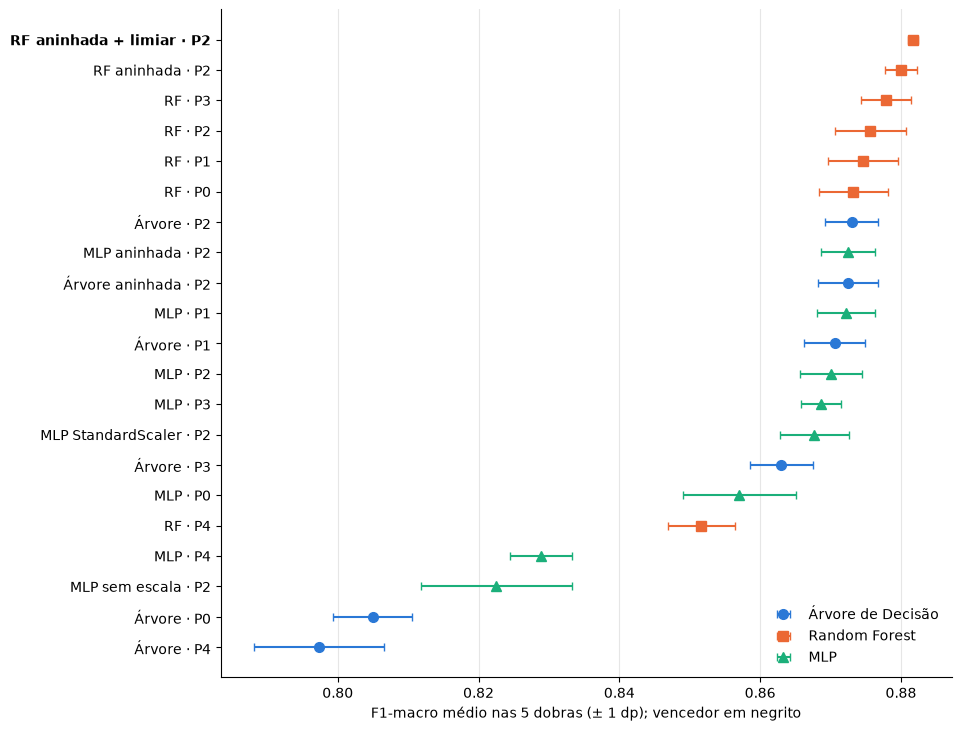

In [20]:
# Seção 5 - 5.3 Aplicação da regra determinística de seleção declarada em 5.1
LIMIAR_EMPATE = 0.0005
f1_por_dobra = por_dobra_etapa3.pivot(index="dobra", columns="rotulo", values="f1_macro")

ranking = (tabela_etapa3.sort_values(
    ["f1_macro_media", "f1_anomaly", "f1_macro_dp", "rotulo"],
    ascending=[False, False, True, True],
).reset_index(drop=True))
ranking["dif_para_lider"] = ranking.f1_macro_media - ranking.f1_macro_media.iloc[0]

# Passo 1: empatados no F1-macro; Passo 2: maior F1 de anomaly; Passo 3: vitórias pareadas e estabilidade.
empatados = ranking[ranking.dif_para_lider > -LIMIAR_EMPATE].copy()
empatados_anomaly = empatados[empatados.f1_anomaly > empatados.f1_anomaly.max() - LIMIAR_EMPATE].copy()
if len(empatados_anomaly) > 1:
    nomes_emp = empatados_anomaly.rotulo.tolist()
    vitorias = {
        r: int(sum((f1_por_dobra[r] > f1_por_dobra[o]).sum() for o in nomes_emp if o != r))
        for r in nomes_emp
    }
    empatados_anomaly["vitorias_pareadas"] = empatados_anomaly.rotulo.map(vitorias)
    empatados_anomaly["sem_reamostragem"] = empatados_anomaly.configuracao.map(
        lambda n: CONFIGURACOES[n]["balanceamento"] is None
    )
    vencedor = empatados_anomaly.sort_values(
        ["vitorias_pareadas", "f1_macro_dp", "sem_reamostragem", "rotulo"],
        ascending=[False, True, False, True],
    ).iloc[0]
else:
    vencedor = empatados_anomaly.iloc[0]

print("Empatados com o líder no F1-macro (diferença < 0,0005):", empatados.rotulo.tolist())
if len(empatados) > 1:
    print("Ainda empatados após o critério do F1 de anomaly (diferença < 0,0005):", empatados_anomaly.rotulo.tolist())
    if len(empatados_anomaly) > 1:
        print("Desempate determinístico por vitórias pareadas:",
              empatados_anomaly.set_index("rotulo")[["vitorias_pareadas", "f1_macro_dp"]].to_dict("index"))
print(f"Vencedor: {vencedor.rotulo} - {vencedor.algoritmo} ({vencedor.variante}, escala {vencedor.escala}), "
      f"{vencedor.configuracao}: F1-macro {vencedor.f1_macro_media:.4f} ± {vencedor.f1_macro_dp:.4f}")

with pd.option_context("display.float_format", "{:.4f}".format, "display.width", 250, "display.max_rows", 30):
    display(ranking[["rotulo", "algoritmo", "variante", "escala", "configuracao", "f1_macro_media", "f1_macro_dp",
                     "dif_para_lider", "f1_anomaly", "precisao_anomaly", "recall_anomaly", "seg_ajuste"]]
            .rename(index=lambda i: i + 1))

# Diferenças pareadas por dobra: vencedor - cada candidato.
dif_vencedor = f1_por_dobra.rsub(f1_por_dobra[vencedor.rotulo], axis=0).drop(columns=vencedor.rotulo)
pareado_vencedor = pd.DataFrame({"dif_media": dif_vencedor.mean(), "dif_min": dif_vencedor.min(),
                                 "dif_max": dif_vencedor.max(), "dobras_vencedor_melhor": (dif_vencedor > 0).sum()})
print(f"Vencedor ({vencedor.rotulo}) - cada candidato, por dobra (5 dobras):")
display(pareado_vencedor.sort_values("dif_media").round(4))

# Visão geral do ranking: F1-macro médio ± dp de todos os candidatos, cor e marcador por algoritmo.
ordem_grafico = ranking.iloc[::-1].reset_index(drop=True)     # melhor no topo
fig, eixo = plt.subplots(figsize=(9.5, 7.2), layout="constrained")
for algoritmo, cor in CORES_ALGORITMO.items():
    parte = ordem_grafico[ordem_grafico.algoritmo == algoritmo]
    eixo.errorbar(parte.f1_macro_media, parte.index, xerr=parte.f1_macro_dp, fmt=MARCADORES_ALGORITMO[algoritmo],
                  color=cor, markersize=7, capsize=3, elinewidth=1.5, linestyle="none", label=algoritmo)
eixo.set_yticks(ordem_grafico.index, ordem_grafico.rotulo)
eixo.get_yticklabels()[int(np.flatnonzero(ordem_grafico.rotulo == vencedor.rotulo)[0])].set_fontweight("bold")
eixo.set_xlabel("F1-macro médio nas 5 dobras (± 1 dp); vencedor em negrito")
eixo.grid(axis="x", color="#e6e6e6", linewidth=0.8)
eixo.set_axisbelow(True)
eixo.spines[["top", "right"]].set_visible(False)
eixo.legend(loc="lower right", frameon=False)
plt.show()


### 5.4 Estabilidade em outra divisão e otimismo da seleção

**Estabilidade:** Reavaliamos o modelo vencedor e os melhores modelos dos outros dois algoritmos usando uma nova divisão em cinco dobras, com semente 137. O objetivo foi verificar se os resultados continuavam semelhantes e se a ordem entre os modelos mudava, não alterando nenhum parâmetro. Como os mesmos dados foram utilizados a avaliação não é totalmente independente.

**Otimismo:** Também analisamos se a escolha do melhor modelo poderia ter sido favorecida pelos resultados das mesmas dobras e para isso, utilizamos dois métodos a correção de Tibshirani e Tibshirani (2009) e a seleção deixando uma dobra de fora. 

Ambos ajudam a estimar o quanto o desempenho do modelo escolhido pode estar acima do esperado. São estimativas aproximadas, pois as dobras não são totalmente independentes.



In [21]:
# Seção 5 - 5.4 Estabilidade na divisão 137 (sem nova escolha) e estimativas do otimismo da seleção
ESPECIFICACOES = {   # (algoritmo, variante, escala) -> como reconstruir o candidato
    ("Árvore de Decisão", "parâmetros padrão", "nenhuma"): dict(modelo=ARVORE_PADRAO, escala=None, grade=None, ajusta_limiar=False),
    ("Árvore de Decisão", "seleção aninhada", "nenhuma"): dict(modelo=ARVORE_PADRAO, escala=None, grade=GRADE_ARVORE, ajusta_limiar=False),
    ("Random Forest", "parâmetros fixados", "nenhuma"): dict(modelo=RF_BASE, escala=None, grade=None, ajusta_limiar=False),
    ("Random Forest", "seleção aninhada", "nenhuma"): dict(modelo=RF_BASE, escala=None, grade=GRADE_RF, ajusta_limiar=False),
    ("Random Forest", "seleção aninhada + limiar", "nenhuma"): dict(modelo=RF_BASE, escala=None, grade=GRADE_RF, ajusta_limiar=True),
    ("MLP", "parâmetros fixados", "log1p + StandardScaler"): dict(modelo=modelo_mlp_m3, escala="log1p_standard", grade=None, ajusta_limiar=False),
    ("MLP", "seleção aninhada", "log1p + StandardScaler"): dict(modelo=modelo_mlp_m3, escala="log1p_standard", grade=GRADE_MLP, ajusta_limiar=False),
    ("MLP", "parâmetros fixados", "StandardScaler"): dict(modelo=modelo_mlp_m3, escala="standard", grade=None, ajusta_limiar=False),
    ("MLP", "parâmetros fixados", "nenhuma"): dict(modelo=modelo_mlp_m3, escala=None, grade=None, ajusta_limiar=False),
}
assert set(ESPECIFICACOES) == set(map(tuple, tabela_etapa3[["algoritmo", "variante", "escala"]].to_numpy()))


def avaliar_candidato(linha, dobras):
    """Reavalia um candidato da tabela da Seção 4 em outras dobras, sem nova escolha de configuração."""
    esp = ESPECIFICACOES[(linha.algoritmo, linha.variante, linha.escala)]
    if esp["grade"] is None:
        res, _ = avaliar_modelo(esp["modelo"], linha.rotulo, {linha.configuracao: CONFIGURACOES[linha.configuracao]},
                                dobras=dobras, escala=esp["escala"])
    elif esp["ajusta_limiar"]:
        _, res, _, _ = selecao_aninhada_com_limiar(
            esp["modelo"], esp["grade"], linha.rotulo, linha.rotulo,
            linha.configuracao, dobras=dobras, escala=esp["escala"],
        )
    else:
        res, _ = selecao_aninhada(esp["modelo"], esp["grade"], linha.rotulo, linha.configuracao,
                                  dobras=dobras, escala=esp["escala"])
    return res


SEMENTE_ESTABILIDADE = 137
DOBRAS_137 = list(StratifiedGroupKFold(n_splits=N_DOBRAS, shuffle=True, random_state=SEMENTE_ESTABILIDADE)
                  .split(X_treino, y_treino, grupos_treino))
for itr, iva in DOBRAS_137:
    assert set(grupos_treino.iloc[itr]).isdisjoint(grupos_treino.iloc[iva])

# O vencedor e o melhor candidato de cada um dos outros algoritmos.
reavaliados = [vencedor] + [ranking[ranking.algoritmo == a].iloc[0] for a in ORDEM_ALGORITMOS if a != vencedor.algoritmo]
inicio = time.perf_counter()
linhas_137, por_dobra_137 = [], []
for linha in reavaliados:
    with warnings.catch_warnings(record=True) as capturados:
        warnings.simplefilter("always")
        res = avaliar_candidato(linha, DOBRAS_137)
    por_dobra_137.append(res.assign(rotulo=linha.rotulo))
    linhas_137.append({"rotulo": linha.rotulo, "f1_macro_42": linha.f1_macro_media, "dp_42": linha.f1_macro_dp,
                       "f1_macro_137": res.f1_macro.mean(), "dp_137": res.f1_macro.std(),
                       "f1_anomaly_42": linha.f1_anomaly, "f1_anomaly_137": res.f1_anomaly.mean(),
                       "avisos_convergencia": sum(issubclass(a.category, ConvergenceWarning) for a in capturados)})
print(f"Reavaliação na divisão 137 concluída em {time.perf_counter() - inicio:.0f} s.")
estabilidade = pd.DataFrame(linhas_137)
estabilidade["f1_macro_duas_divisoes"] = (estabilidade.f1_macro_42 + estabilidade.f1_macro_137) / 2
por_dobra_137 = pd.concat(por_dobra_137, ignore_index=True)
f1_137 = por_dobra_137.pivot(index="dobra", columns="rotulo", values="f1_macro")
dif_137 = f1_137.rsub(f1_137[vencedor.rotulo], axis=0).drop(columns=vencedor.rotulo)
with pd.option_context("display.float_format", "{:.4f}".format, "display.width", 250):
    display(estabilidade)
    print(f"Divisão 137 - vencedor ({vencedor.rotulo}) - cada candidato, por dobra:")
    display(pd.DataFrame({"dif_media": dif_137.mean(), "dobras_vencedor_melhor": (dif_137 > 0).sum()}))

# (a) Tibshirani e Tibshirani (2009): excesso médio do melhor candidato de cada dobra sobre o vencedor.
melhor_da_dobra = f1_por_dobra.max(axis=1)
vies_selecao = (melhor_da_dobra - f1_por_dobra[vencedor.rotulo]).mean()
# (b) Seleção deixando uma dobra de fora: escolhe pela média das outras quatro e mede só na dobra deixada de fora.
selecao_fora = pd.DataFrame([{"dobra": k, "escolhido_pelas_outras_4": f1_por_dobra.drop(index=k).mean().idxmax(),
                              "melhor_nesta_dobra": f1_por_dobra.loc[k].idxmax(),
                              "f1_macro_melhor": melhor_da_dobra[k]} for k in f1_por_dobra.index])
selecao_fora["f1_macro_escolhido"] = [f1_por_dobra.loc[k, c] for k, c in
                                      zip(selecao_fora.dobra, selecao_fora.escolhido_pelas_outras_4)]
with pd.option_context("display.float_format", "{:.4f}".format, "display.width", 250):
    display(selecao_fora)
otimismo = pd.Series({
    "F1-macro do vencedor (máximo das médias)": round(vencedor.f1_macro_media, 4),
    "Viés estimado (Tibshirani e Tibshirani)": round(vies_selecao, 4),
    "F1-macro corrigido (máximo - viés)": round(vencedor.f1_macro_media - vies_selecao, 4),
    "F1-macro da seleção deixando uma dobra de fora": round(selecao_fora.f1_macro_escolhido.mean(), 4),
    "Candidatos comparados": f1_por_dobra.shape[1],
    "Dobras em que o vencedor é o melhor candidato": int((f1_por_dobra.idxmax(axis=1) == vencedor.rotulo).sum()),
}, name="valor", dtype=object)
display(otimismo.to_frame())


Reavaliação na divisão 137 concluída em 392 s.


,rotulo,f1_macro_42,dp_42,f1_macro_137,dp_137,f1_anomaly_42,f1_anomaly_137,avisos_convergencia,f1_macro_duas_divisoes
0,RF aninhada + limiar · P2,0.8818,0.0007,0.8818,0.0037,0.7778,0.7779,0,0.8818
1,Árvore · P2,0.8730,0.0038,0.8706,0.0034,0.7612,0.7568,0,0.8718
2,MLP aninhada · P2,0.8725,0.0038,0.8710,0.0060,0.7601,0.7571,0,0.8717


Divisão 137 - vencedor (RF aninhada + limiar · P2) - cada candidato, por dobra:


,dif_media,dobras_vencedor_melhor
rotulo,,
MLP aninhada · P2,0.0109,5
Árvore · P2,0.0112,5


,dobra,escolhido_pelas_outras_4,melhor_nesta_dobra,f1_macro_melhor,f1_macro_escolhido
0,1,RF aninhada + limiar · P2,RF aninhada + limiar · P2,0.8821,0.8821
1,2,RF aninhada + limiar · P2,RF aninhada + limiar · P2,0.8813,0.8813
2,3,RF aninhada + limiar · P2,RF aninhada · P2,0.8833,0.8828
3,4,RF aninhada + limiar · P2,RF aninhada + limiar · P2,0.8815,0.8815
4,5,RF aninhada + limiar · P2,RF aninhada + limiar · P2,0.8810,0.8810


,valor
F1-macro do vencedor (máximo das médias),0.8818
Viés estimado (Tibshirani e Tibshirani),0.0001
F1-macro corrigido (máximo - viés),0.8817
F1-macro da seleção deixando uma dobra de fora,0.8818
Candidatos comparados,21
Dobras em que o vencedor é o melhor candidato,4


### 5.5 Configuração reproduzível para a etapa 4

`CONFIG_VENCEDOR_ETAPA3` reúne todas as informações necessárias para reconstruir o modelo vencedor de forma independente na Etapa 4: dados (`sha256`), colunas excluídas, pré-processamento, escala, limiar de decisão, parâmetros do modelo, sementes e versões das bibliotecas.

As funções `construir_pipeline_vencedor()` e `prever_vencedor()` montam o pipeline a partir do dicionário e aplicam o limiar registrado. Para confirmar a reprodutibilidade exata, reconstruímos o vencedor do zero na primeira dobra e comparamos sua matriz de confusão com a registrada na seleção.


In [22]:
# Seção 5 - 5.5 Configuração reproduzível do vencedor e verificação de reconstrução
esp_vencedor = ESPECIFICACOES[(vencedor.algoritmo, vencedor.variante, vencedor.escala)]
cfg_vencedor = CONFIGURACOES[vencedor.configuracao]
if esp_vencedor["grade"] is None:
    modelo_final = clone(esp_vencedor["modelo"])
    limiar_final = 0.5
    origem_parametros = "fixados antes da execução"
elif esp_vencedor["ajusta_limiar"]:
    # Mesmo procedimento interno da seleção aninhada sobre todo o treino (3 dobras por grupos, semente 42).
    melhor_final, _, limiar_final, f1_lim_int = escolher_parametros(
        esp_vencedor["modelo"], esp_vencedor["grade"], vencedor.configuracao,
        X_treino, y_treino, grupos_treino, esp_vencedor["escala"], retornar_limiar=True,
    )
    modelo_final = clone(esp_vencedor["modelo"]).set_params(**melhor_final)
    origem_parametros = (f"seleção interna em todo o treino (3 dobras por grupos, semente {SEMENTE}): "
                         f"{melhor_final}; limiar_decisao={limiar_final:.2f} (F1 interno {f1_lim_int:.4f})")
else:
    melhor_final, _ = escolher_parametros(
        esp_vencedor["modelo"], esp_vencedor["grade"], vencedor.configuracao,
        X_treino, y_treino, grupos_treino, esp_vencedor["escala"],
    )
    modelo_final = clone(esp_vencedor["modelo"]).set_params(**melhor_final)
    limiar_final = 0.5
    origem_parametros = f"seleção interna em todo o treino (3 dobras por grupos, semente {SEMENTE}): {melhor_final}"

CLASSES_MODELO = {c.__name__: c for c in (DecisionTreeClassifier, RandomForestClassifier, MLPClassifier)}
CONFIG_VENCEDOR_ETAPA3 = {
    "candidato": vencedor.rotulo,
    "algoritmo": vencedor.algoritmo,
    "classe_modelo": type(modelo_final).__name__,
    "parametros_modelo": modelo_final.get_params(deep=False),
    "origem_parametros": origem_parametros,
    "limiar_decisao": float(limiar_final),
    "combinacao": vencedor.configuracao,
    "pre_processamento": {k: v for k, v in cfg_vencedor.items() if k not in ("linhas_treino", "balanceamento")},
    "escala": esp_vencedor["escala"],
    "linhas_treino": cfg_vencedor["linhas_treino"],
    "balanceamento": cfg_vencedor["balanceamento"],
    "colunas_fora_dos_preditores": [COL_ID, COL_ROTULO, *SINAIS_OPERACIONAIS],
    "dados": {"arquivo": "data/treino.csv", "sha256": HASH_TREINO, "linhas": len(X_treino),
              "atributos": X_treino.shape[1]},
    "sementes": {"dobras": SEMENTE, "amostradores": SEMENTE, "modelo": SEMENTE},
    "validacao_interna": {"esquema": f"StratifiedGroupKFold(n_splits={N_DOBRAS}, shuffle=True, random_state={SEMENTE}), "
                                     "grupos = registros com atributos idênticos",
                          "assinatura_dobras": ASSINATURA_DOBRAS,
                          "f1_macro_media": round(float(vencedor.f1_macro_media), 4),
                          "f1_macro_dp": round(float(vencedor.f1_macro_dp), 4)},
    "versoes": VERSOES,
}


def construir_pipeline_vencedor(config=CONFIG_VENCEDOR_ETAPA3):
    """Pipeline não ajustado do vencedor, montado apenas a partir do dicionário de configuração.

    Uso na etapa 4: X, y = carregar_treino(); X_fit, y_fit = filtrar_linhas_treino(X, y, config["linhas_treino"]);
    pipe = construir_pipeline_vencedor(config).fit(X_fit, y_fit); prever_vencedor(pipe, X_alvo, config["limiar_decisao"]).
    """
    modelo = CLASSES_MODELO[config["classe_modelo"]](**config["parametros_modelo"])
    cfg = {**config["pre_processamento"], "linhas_treino": config["linhas_treino"],
           "balanceamento": config["balanceamento"]}
    return montar_pipeline(cfg, modelo, escala=config["escala"])


def prever_vencedor(pipeline_ajustado, X, limiar=None):
    """Gera previsões binárias (0=normal, 1=anomaly) respeitando o limiar registrado."""
    if limiar is None:
        limiar = CONFIG_VENCEDOR_ETAPA3["limiar_decisao"]
    if abs(limiar - 0.5) < 1e-12:
        return pipeline_ajustado.predict(X)
    return (pipeline_ajustado.predict_proba(X)[:, 1] >= limiar).astype(int)


# Reconstrução do zero na dobra 1 e comparação com o registrado na seleção.
itr, iva = INDICES_DOBRAS[0]
registrado = por_dobra_etapa3[(por_dobra_etapa3.rotulo == vencedor.rotulo) & (por_dobra_etapa3.dobra == 1)].iloc[0]
if esp_vencedor["grade"] is None:
    X_fit, y_fit = filtrar_linhas_treino(X_treino.iloc[itr], y_treino.iloc[itr], CONFIG_VENCEDOR_ETAPA3["linhas_treino"])
    pipe_rec = construir_pipeline_vencedor().fit(X_fit, y_fit)
    reconstruido = metricas_classificacao(y_treino.iloc[iva], prever_vencedor(pipe_rec, X_treino.iloc[iva], limiar=0.5))
elif esp_vencedor["ajusta_limiar"]:
    _, por_dobra_rec, _, _ = selecao_aninhada_com_limiar(
        esp_vencedor["modelo"], esp_vencedor["grade"], vencedor.rotulo, vencedor.rotulo,
        vencedor.configuracao, dobras=[(itr, iva)], escala=esp_vencedor["escala"],
    )
    reconstruido = por_dobra_rec.iloc[0]
else:
    reconstruido = selecao_aninhada(esp_vencedor["modelo"], esp_vencedor["grade"], vencedor.rotulo,
                                    vencedor.configuracao, dobras=[(itr, iva)], escala=esp_vencedor["escala"])[0].iloc[0]
matriz = ["TN", "FP", "FN", "TP"]
assert [int(reconstruido[c]) for c in matriz] == [int(registrado[c]) for c in matriz]
assert construir_pipeline_vencedor().named_steps["modelo"].get_params() == modelo_final.get_params()

print(json.dumps(CONFIG_VENCEDOR_ETAPA3, indent=2, ensure_ascii=False, default=str))
display(pd.DataFrame({"registrado na seleção": [int(registrado[c]) for c in matriz] + [round(registrado.f1_macro, 4)],
                      "reconstruído do dicionário": [int(reconstruido[c]) for c in matriz]
                                                    + [round(reconstruido["f1_macro"], 4)]},
                     index=matriz + ["f1_macro"], dtype=object).T)
print("Reconstrução aprovada: o dicionário reproduz a dobra 1 do vencedor.")


{
  "candidato": "RF aninhada + limiar · P2",
  "algoritmo": "Random Forest",
  "classe_modelo": "RandomForestClassifier",
  "parametros_modelo": {
    "bootstrap": true,
    "ccp_alpha": 0.0,
    "class_weight": {
      "0": 1.0,
      "1": 4.0
    },
    "criterion": "gini",
    "max_depth": null,
    "max_features": 0.3,
    "max_leaf_nodes": null,
    "max_samples": null,
    "min_impurity_decrease": 0.0,
    "min_samples_leaf": 1,
    "min_samples_split": 2,
    "min_weight_fraction_leaf": 0.0,
    "monotonic_cst": null,
    "n_estimators": 300,
    "n_jobs": -1,
    "oob_score": false,
    "random_state": 42,
    "verbose": 0,
    "warm_start": false
  },
  "origem_parametros": "seleção interna em todo o treino (3 dobras por grupos, semente 42): {'max_features': 0.3, 'min_samples_leaf': 1, 'class_weight': {0: 1.0, 1: 4.0}}; limiar_decisao=0.37 (F1 interno 0.8806)",
  "limiar_decisao": 0.37,
  "combinacao": "P2 P1 + raras agrupadas",
  "pre_processamento": {
    "normalizar_catego

,TN,FP,FN,TP,f1_macro
registrado na seleção,12927,224,153,663,0.8821
reconstruído do dicionário,12927,224,153,663,0.8821


Reconstrução aprovada: o dicionário reproduz a dobra 1 do vencedor.


### 5.6 Resultados e justificativa — Seção 5 (Seleção e auditoria)

**Auditoria (5.2).** Todas as 8 verificações passaram integralmente:
- `treino.csv` tem `sha256` `9713c75938ef1e9e` e os objetos `X_treino`/`y_treino` em memória são idênticos ao CSV;
- os `46` preditores excluem `id`, `class` e os três sinais operacionais;
- as dobras preservam a assinatura `8a814c72d149c698`, formam partição completa e mantêm grupos disjuntos;
- todas as `105` avaliações usaram a validação inteira sem filtro nem reamostragem;
- na dobra 1 de P0–P4, as medianas do `SimpleImputer` e as contagens de amostra pós-ROS/RUS conferem exatamente com o treino filtrado da dobra;
- nenhuma das `19` células executadas até a auditoria cita os arquivos de teste ou submissão.

**Vencedor (5.3).** Aplicando a regra determinística de 5.1 sem acionar tempo de máquina:
1. **`RF aninhada + limiar · P2`** vence isoladamente já no critério primário (**F1-macro `0,8818 ± 0,0007`**), com vantagem de `+0,0018` sobre o 2º colocado (`RF aninhada · P2`, `0,8800 ± 0,0022`) e `+0,0039` sobre o 3º (`RF · P3`, `0,8779 ± 0,0036`) — acima do limiar de empate `0,0005`.
2. **Comparação pareada nas 5 dobras (divisão 42):** o vencedor supera `RF aninhada · P2` em `4 de 5` dobras (diferença média `+0,0018`, de `-0,0005` a `+0,0042`) e supera **todos os outros 19 candidatos em 5 de 5 dobras**, incluindo `RF · P3` (`+0,0039`), `Árvore · P2` (`+0,0088`) e `MLP aninhada · P2` (`+0,0092`).

**Configuração vencedora:**
- **Algoritmo:** `RandomForestClassifier(n_estimators=300, max_features=0.3, min_samples_leaf=1, max_depth=None, class_weight={0: 1.0, 1: 4.0}, bootstrap=True, random_state=42, n_jobs=-1)`.
- **Limiar de decisão:** `0,37` (selecionado internamente sobre as 3 dobras internas por grupo sobre todo o treino, F1-macro interno `0,8806`).
- **Pré-processamento:** combinação P2 (`NormalizarCategorias`, `TratarForaDominio(modo="ausente")`, `RemoverRedundantes`, mediana numérica, categoria `__ausente__`, `OneHotEncoder` com `min_frequency=100`, filtro `sem_conflitos` aplicado exclusivamente no treino).
- **Balanceamento por reamostragem e escala:** nenhum (a ponderação `class_weight={0: 1.0, 1: 4.0}` e o limiar `0,37` compensam o deslocamento de prevalência sem duplicar nem descartar linhas).
- **Colunas fora dos preditores:** `id`, `class` e os três sinais operacionais.

**Força da evidência, estabilidade e otimismo (5.4).**
- **Divisão 137 (estabilidade):** sem nova seleção de família ou grade, `RF aninhada + limiar · P2` manteve **`0,8818 ± 0,0037`** (`F1 anomaly = 0,7779`), superando `Árvore · P2` (`0,8706 ± 0,0034`, `+0,0112` em `5/5` dobras) e `MLP aninhada · P2` (`0,8710 ± 0,0060`, `+0,0109` em `5/5` dobras), com 0 avisos de convergência.
- **Otimismo da seleção:** entre os `21` candidatos comparados, a correção de Tibshirani e Tibshirani (2009) estimou viés de apenas **`0,0001`** (`F1-macro corrigido = 0,8817`), e a seleção deixando uma dobra de fora também resultou em **`0,8818`**, pois o vencedor foi o melhor candidato individual em `4 de 5` dobras. Permanecem as ressalvas de que decisões anteriores da Etapa 2 usaram estas dobras e de que a divisão 137 reutiliza os mesmos registros; o desempenho real no teste oficial será conhecido somente após a avaliação da professora.

**Reprodutibilidade (5.5).** `CONFIG_VENCEDOR_ETAPA3` registra dados (`sha256 = 9713c75938ef1e9e513975f256d65a80c4b05df533d35336c67387020bf76b7f`), colunas excluídas, pré-processamento, limiar de decisão (`0,37`), parâmetros com chaves inteiras `class_weight={0: 1.0, 1: 4.0}`, sementes e versões. Reconstruído do zero na dobra 1 a partir do dicionário, o procedimento reproduziu exatamente a matriz registrada: `TN 12.927, FP 224, FN 153, TP 663, F1-macro 0,8821`.

**Roteiro para a Etapa 4:**
1. Definir de forma autocontida no notebook 04 as classes/funções da seção 1.1 (`NormalizarCategorias`, `TratarForaDominio`, `RemoverRedundantes`, `Log1pNumerico`, `montar_preprocessamento`, `filtrar_linhas_treino`) e `construir_pipeline_vencedor` / `prever_vencedor`.
2. Carregar `treino.csv` sem os sinais operacionais e aplicar `filtrar_linhas_treino(X, y, "sem_conflitos")` em todo o treino.
3. Ajustar `construir_pipeline_vencedor()` (com `class_weight={0: 1.0, 1: 4.0}` e `max_features=0.3`) sobre esse treino filtrado.
4. Aplicar `prever_vencedor(pipe, X_teste, limiar=0.37)` sobre `teste_sem_rotulo.csv` sem filtrar nem reamostrar e validar o formato de `submissao_10.csv`.

**Limitações e pendências.**
- A exclusão preventiva dos sinais operacionais deve ser formalizada com a professora; caso ela confirme que estão disponíveis antes da predição, os experimentos podem ser reavaliados na Etapa 4.
- Nenhuma métrica do teste oficial foi usada ou produzida nesta etapa.

**Uso de IA.** Esta etapa teve apoio de Claude Code (Anthropic), OpenAI Codex e Gemini (Antigravity) para implementação, padronização metodológica, execução integral em kernel limpo e revisão dos textos e auditorias. Os integrantes da equipe devem revisar os resultados e registrar as atribuições finais no relatório da Etapa 4.


## Revisão conjunta

Cada membro deve explicar sua contribuição e revisar a integração com os demais. Conferir os requisitos da etapa, resultados reais, ausência de vazamento, reprodução e declaração de uso de IA antes de entregar.
